In [48]:
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import (
    LinearRegression, SGDRegressor, HuberRegressor, TheilSenRegressor, RANSACRegressor, QuantileRegressor
)
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR, LinearSVR, NuSVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from mpl_toolkits.mplot3d import Axes3D
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns
import matplotlib.pyplot as plt
import itertools
import random
from scipy.stats import pearsonr
import json


import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import Input
from tensorflow.keras.optimizers import SGD, Adam



from scipy.stats import f_oneway




df = pd.read_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/DataModels.csv', index_col='ID')
categorical_features=pd.read_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/DataModels_categorical_features.csv', index_col='ID')
numerical_features=pd.read_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/DataModels_numercial_features.csv', index_col='ID')


---
## 🛑 Task 2.3: Charges

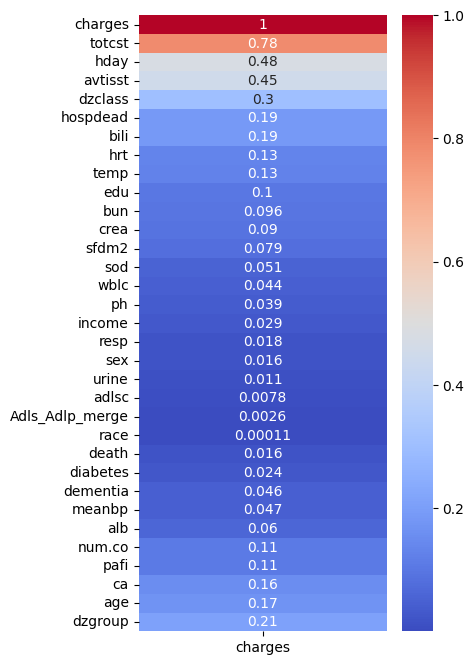

In [49]:
plt.figure(figsize=(4, 8))
sns.heatmap(df.corr()["charges"].sort_values(ascending=False).abs().to_frame(), annot=True, cmap='coolwarm')
plt.show()

The “totcst” reflects the total operating cost of the company, so it is reasonable to expect a high correlation with the cost to patients. However, we do not remove this column, as it represents a set initial price. Instead, “charges” corresponds to the final amount charged to the patient. Given this, we know that the correlation between both variables is high, but not perfect (not equal to 1). The “totcst” variable gives us some fundamental context about the initial cost, while the other variables allow us to predict fluctuations in the final cost to patients.

---
### 🛑  Model Analysis

In [50]:
target=df['charges']
features=df.drop(['charges'],axis=1)
categorical_features_cols= categorical_features.columns
numerical_features_cols = numerical_features.columns.drop(['charges']).tolist()



In [51]:
# Definir StratifiedKFold (estratificando la variable objetivo discretizada)
bins = pd.qcut(target, q=5, labels=False)  # Discretizar en quintiles
kfold_external = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
data_dict = {}
# Crear un DataFrame para guardar resultados
evaluation_metrics_scaled = pd.DataFrame(columns=['Model', 'MAE_VAL', 'MAPE_VAL', 'RMSE_VAL', 'R2_VAL', 'R2_adjusted_VAL', 'MAE_TRAIN', 'MAPE_TRAIN', 'RMSE_TRAIN', 'R2_TRAIN', 'R2_adjusted_TRAIN'])

# Función para calcular métricas
def evaluate_model(y_true, y_pred, n, p):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    r2 = r2_score(y_true, y_pred)
    r2_adjusted = 1 - ((1 - r2) * (n - 1) / (n - p - 1))
    return mae, mape, rmse, r2, r2_adjusted

# Modelos de regresión
models = {
    "Linear Regression": LinearRegression(),
    "Quantile Regression": QuantileRegressor(quantile=0.5),
    "Polynomial Regression (Degree=2)": Pipeline([
        ("poly_features", PolynomialFeatures(degree=2)),
        ("linear_regression", LinearRegression())
    ]),
    "Linear SVR": LinearSVR(random_state=42),
    "SVR": SVR(),
    "NuSVR": NuSVR(),
    "SGD Regression": SGDRegressor(random_state=42),
    "Nearest Neighbor Regression": KNeighborsRegressor(),
    "Decision Tree Regression": DecisionTreeRegressor(random_state=42),
    "RANSAC Regression": RANSACRegressor(random_state=42),
    "Theil-Sen Regression": TheilSenRegressor(random_state=42),
    "Huber Regressor": HuberRegressor()
}

for fold, (train_val_index, test_index) in enumerate(kfold_external.split(features, bins)):
    fold_external_dict = {}
    # Dividir en conjunto de prueba y conjunto de entrenamiento/validación
    X_train_val, X_test = features.iloc[train_val_index], features.iloc[test_index]
    y_train_val, y_test = target.iloc[train_val_index], target.iloc[test_index]
    
    # Índices alineados 
    bins_train_val = bins.iloc[train_val_index]
    
    # Inicialización de KFold interno
    kfold_internal = StratifiedKFold(n_splits=2, shuffle=True, random_state=42)
    number=1
    for train_index, val_index in kfold_internal.split(X_train_val, bins_train_val):
        # División en conjuntos de entrenamiento y validación
        X_train = X_train_val.iloc[train_index]
        y_train = y_train_val.iloc[train_index]
        X_val = X_train_val.iloc[val_index]
        y_val = y_train_val.iloc[val_index]

        # Separar variables cuantitativas y cualitativas
        X_train_quantitative = X_train[numerical_features_cols]
        X_val_quantitative = X_val[numerical_features_cols]
        X_test_quantitative = X_test[numerical_features_cols]
        X_train_qualitative = pd.get_dummies(X_train[categorical_features_cols], drop_first=True)
        X_val_qualitative = pd.get_dummies(X_val[categorical_features_cols], drop_first=True)
        X_test_qualitative = pd.get_dummies(X_test[categorical_features_cols], drop_first=True)
        
        # Normalizar datos
        # Initialize the scaler
        scaler = StandardScaler()

        # Fit and transform on the training data, preserving the index
        X_scaled_train = scaler.fit_transform(X_train_quantitative)
        X_scaled_train = pd.DataFrame(X_scaled_train, columns=X_train_quantitative.columns, index=X_train_quantitative.index)

        # Transform validation data (using the same scaler fitted on training data), preserving the index
        X_scaled_val = scaler.transform(X_val_quantitative)
        X_scaled_val = pd.DataFrame(X_scaled_val, columns=X_val_quantitative.columns, index=X_val_quantitative.index)

        # Transform test data (using the same scaler fitted on training data), preserving the index
        X_scaled_test = scaler.transform(X_test_quantitative)
        X_scaled_test = pd.DataFrame(X_scaled_test, columns=X_test_quantitative.columns, index=X_test_quantitative.index)

        X_scaled_train=pd.concat([X_scaled_train,X_train_qualitative],axis=1)
        X_scaled_val=pd.concat([X_scaled_val,X_val_qualitative],axis=1)
        X_scaled_test=pd.concat([X_scaled_test,X_test_qualitative],axis=1)

        # Guardar los datos procesados
        fold_internal_key = f'Fold_Interno_{number}'
        fold_external_dict[fold_internal_key] = {
            'Train_X': X_scaled_train,
            'Train_Y': y_train,
            'Validation_X': X_scaled_val,
            'Validation_Y': y_val,
            'Test_X': X_scaled_test,
            'Test_Y': y_test
        }

        # Guardar el fold externo con todos los internos
        fold_external_key = f'Fold_Externo_{fold}'
        data_dict[fold_external_key] = fold_external_dict

        for model_name, model in models.items():
            # Ajustar el modelo y realizar predicciones
            model.fit(X_scaled_train, y_train)
            y_pred = model.predict(X_scaled_val)

            # Calcular las métricas para el set de validación
            n, p = X_scaled_test.shape
            mae, mape, rmse, r2, r2_adjusted = evaluate_model(y_val, y_pred, n, p)

           

            # Calculando las métricas para el conjunto de train
            mae_train, mape_train, rmse_train, r2_train, r2_adjusted_train = evaluate_model(y_train, model.predict(X_scaled_train), n, p)

            # Registrar las métricas
            model_row = pd.DataFrame([{
                'Model': model_name,
                'MAE_VAL': mae,
                'MAPE_VAL': mape,
                'RMSE_VAL': rmse,
                'R2_VAL': r2,
                'R2_adjusted_VAL': r2_adjusted,
                'MAE_TRAIN': mae_train,
                'MAPE_TRAIN': mape_train,
                'RMSE_TRAIN': rmse_train,
                'R2_TRAIN': r2_train,
                'R2_adjusted_TRAIN': r2_adjusted_train

            }])
            evaluation_metrics_scaled = pd.concat([evaluation_metrics_scaled, model_row], ignore_index=True)
        number=number+1

/var/folders/vr/_v9wq92941bflv75jsh8kq800000gn/T/ipykernel_66915/527831605.py:127: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  evaluation_metrics_scaled = pd.concat([evaluation_metrics_scaled, model_row], ignore_index=True)


In [52]:
evaluation_metrics_scaled.groupby('Model').mean().sort_values('R2_adjusted_VAL', ascending=False)

,MAE_VAL,MAPE_VAL,RMSE_VAL,R2_VAL,R2_adjusted_VAL,MAE_TRAIN,MAPE_TRAIN,RMSE_TRAIN,R2_TRAIN,R2_adjusted_TRAIN
Model,,,,,,,,,,
Linear Regression,26034.785410,97.963526,60825.851073,0.651953,0.645511,25748.538283,97.370317,60010.456082,0.661150,0.654878
Theil-Sen Regression,21250.578425,59.482882,61653.624450,0.642407,0.635788,21103.600675,58.933630,61437.788875,0.644878,0.638304
SGD Regression,28384.409675,111.644495,61814.510879,0.640546,0.633892,28015.340527,110.342892,60827.482398,0.651741,0.645295
Polynomial Regression (Degree=2),32199.164705,140.597190,64974.712080,0.602918,0.595568,24755.903077,115.986449,47201.152192,0.790155,0.786271
Huber Regressor,18471.324278,33.454900,65413.865066,0.597438,0.589987,18413.803780,33.282725,65365.386463,0.598013,0.590572
RANSAC Regression,24026.310585,75.330939,67122.079042,0.575755,0.567902,23733.219201,75.051379,66935.716231,0.577938,0.570125
Nearest Neighbor Regression,32490.538567,92.924692,72994.375843,0.499091,0.489820,26432.358898,74.361802,59073.398744,0.671814,0.665740
Decision Tree Regression,24884.851870,37.814160,75944.411393,0.454500,0.444402,0.000000,0.000000,0.000000,1.000000,1.000000
NuSVR,50748.086652,220.829126,105623.764591,-0.048860,-0.068275,50748.293712,220.825697,105623.685888,-0.048818,-0.068232


---
# Complexity Analysis

Given the analysis of the performance metrics of both the linear and non-linear regression models, we have identified those with the best performance. From this, we have decided to examine their complexity to assess whether by adjusting it we could further optimize their performance.

---

# Linear Models
---

The complexity of the models depends on the number of features used. In this case, with 32 features, the number of possible combinations for each reduction in features is given by \( 32C(32-i) \), which results in a large number of possible combinations. To reduce computational load, we have opted for a sampling of the combinations, ensuring that 95% confidence is maintained. This allows us to optimize the process without significantly compromising the model's accuracy.


````
def calculate_sample_size(Z, p, E, N):
    # Paso 1: Tamaño de muestra para población infinita
    n0 = (Z**2 * p * (1 - p)) / (E**2)

    # Paso 2: Ajuste para población finita
    n = n0 * (N / (N + n0 - 1))
    return n
    
# Diccionario para almacenar las combinaciones
combinations_dict = {f'F{i}': [] for i in range(32, 1, -1)}

# Generamos las combinaciones y las guardamos en el diccionario
for i in range(32, 1, -1):
    # Usamos un generador en lugar de una lista para evitar problemas de memoria
    combinations = itertools.combinations(features.columns, i)
    Z = 1.96  # Nivel de confianza (95%)
    p = 0.5   # Proporción esperada (conservadora)
    E = 0.05  # Margen de error
    N = len(list(combinations))  # Necesitamos obtener la longitud de las combinaciones
    sample_size = calculate_sample_size(Z, p, E, N)
    
    # Volver a crear el generador para seleccionar la muestra
    combinations = itertools.combinations(features.columns, i)
    muestra = random.sample(list(combinations), int(sample_size))  # Convierte el generador en lista para el muestreo
    combinations_dict[f'F{i}'] = muestra
# Guardar en un archivo JSON
with open('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/Regression Task2/T2.3_PREDICTION_CHARGES/Combinatoria de features.json', 'w') as file:
    json.dump(combinations_dict, file)


In [53]:
with open('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/Regression Task2/T2.3_PREDICTION_CHARGES/Combinatoria de features.json', 'r') as file:
    combinations_dict = json.load(file)
 # Lo hemos guardado en un json file para no tener que correrlo cada vez y ademas de que nos perimte guardar fácilmente un diccionario
for i in combinations_dict:
    print(f"Combinaciones de {i}: {len(combinations_dict[i])}")

Combinaciones de F32: 1
Combinaciones de F31: 29
Combinaciones de F30: 216
Combinaciones de F29: 356
Combinaciones de F28: 380
Combinaciones de F27: 383
Combinaciones de F26: 383
Combinaciones de F25: 384
Combinaciones de F24: 384
Combinaciones de F23: 384
Combinaciones de F22: 384
Combinaciones de F21: 384
Combinaciones de F20: 384
Combinaciones de F19: 384
Combinaciones de F18: 384
Combinaciones de F17: 384
Combinaciones de F16: 384
Combinaciones de F15: 384
Combinaciones de F14: 384
Combinaciones de F13: 384
Combinaciones de F12: 384
Combinaciones de F11: 384
Combinaciones de F10: 384
Combinaciones de F9: 384
Combinaciones de F8: 384
Combinaciones de F7: 384
Combinaciones de F6: 383
Combinaciones de F5: 383
Combinaciones de F4: 380
Combinaciones de F3: 356
Combinaciones de F2: 216


## Linear Regresion Analysis
- We determined that the number of variables determines the complexity of the model

```
df_modelo_evaluacion_fit_linear=pd.DataFrame(columns=['Model','n_features','MSE_TRAIN','MSE_VAL','R2_TRAIN','R2_VAL'])
# Iterar sobre cada pliegue externo e interno en el diccionario
for fold_externo, internos in data_dict.items():
    for fold_interno, data in internos.items():      
        for combinations in combinations_dict:
            for value in combinations_dict[combinations]:
                # Separar variables cuantitativas y cualitativas
                X_train = data['Train_X'][list(value)]
                y_train = data['Train_Y']
                X_val = data['Validation_X'][list(value)]
                y_val = data['Validation_Y']
                X_test = data['Test_X'][list(value)]
                y_test = data['Test_Y']
                # Ajustar el modelo
                model = LinearRegression()
                model.fit(X_train, y_train)
                # Realizar predicciones
                y_train_pred = model.predict(X_train)
                y_val_pred = model.predict(X_val)
                # Calcular métricas
                mse_train = mean_squared_error(y_train, y_train_pred)
                mse_val = mean_squared_error(y_val, y_val_pred)
                r2_train = r2_score(y_train, y_train_pred)
                r2_val = r2_score(y_val, y_val_pred)
                # Registrar resultados
                row = pd.DataFrame([{
                    'Model': 'Linear Regression',
                    'n_features': len(value),
                    'MSE_TRAIN': mse_train,
                    'MSE_VAL': mse_val,
                    'R2_TRAIN': r2_train,
                    'R2_VAL': r2_val
                }])
                df_modelo_evaluacion_fit_linear = pd.concat([df_modelo_evaluacion_fit_linear, row], ignore_index=True)

df_modelo_evaluacion_fit_linear.to_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/Regression Task2/T2.3_PREDICTION_CHARGES/df_modelo_evaluacion_fit_linear.csv')

In [54]:
df_modelo_evaluacion_fit_linear=pd.read_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/Regression Task2/T2.3_PREDICTION_CHARGES/df_modelo_evaluacion_fit_linear.csv')

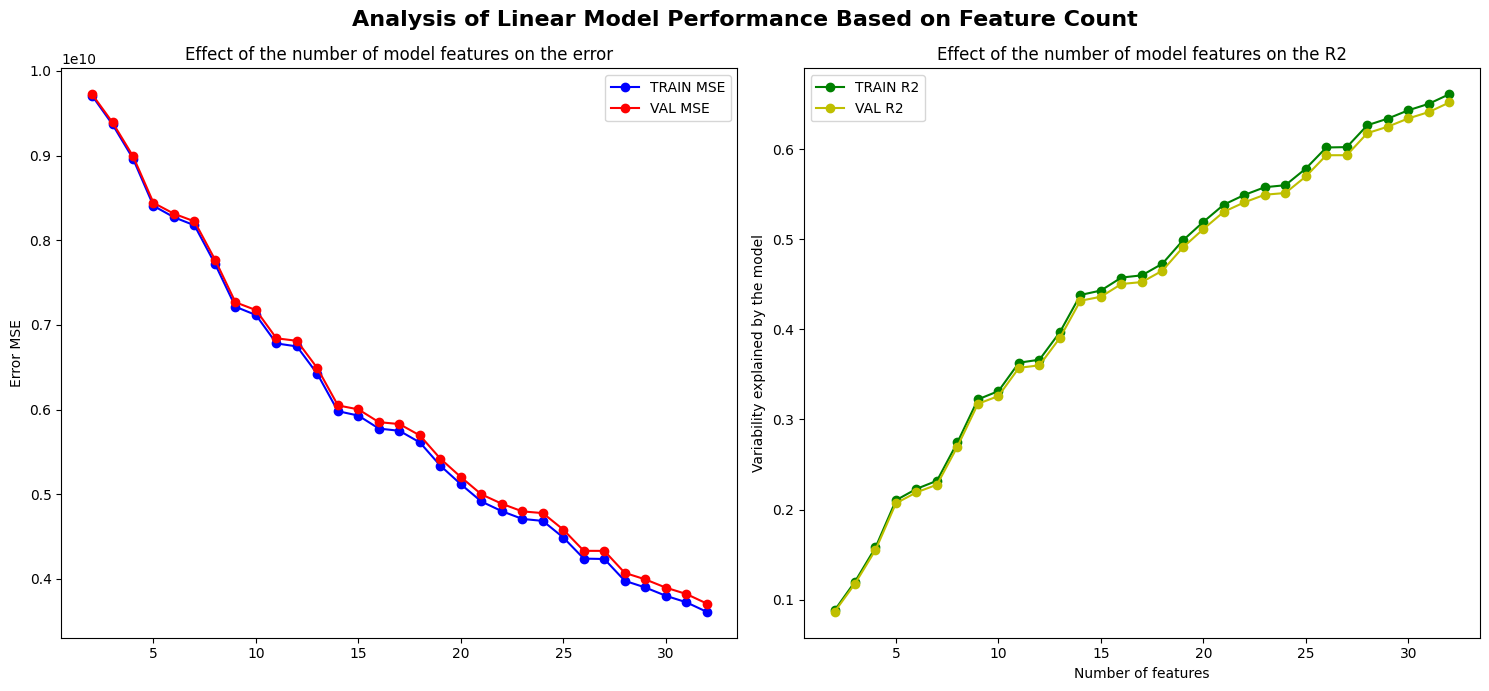

In [55]:
# Agrupar por 'Model' y 'n_features', calculando la media del MSE_train
df_grouped_linear = df_modelo_evaluacion_fit_linear.groupby(['Model', 'n_features']).mean().reset_index().sort_values('n_features',ascending=False)
fig, axs = plt.subplots(1, 2, figsize=(15, 7), sharex=True)
fig.suptitle("Analysis of Linear Model Performance Based on Feature Count", fontsize=16, fontweight='bold')

# Primer subplot: MSE
axs[0].plot(df_grouped_linear['n_features'], df_grouped_linear['MSE_TRAIN'], marker='o', color='b', linestyle='-', label='TRAIN MSE')
axs[0].plot(df_grouped_linear['n_features'], df_grouped_linear['MSE_VAL'], marker='o', color='r', linestyle='-', label='VAL MSE')
axs[0].invert_xaxis()  # Invertir el eje x
axs[0].set_title("Effect of the number of model features on the error")
axs[0].legend()
axs[0].set_ylabel('Error MSE')

# Segundo subplot: R2
axs[1].plot(df_grouped_linear['n_features'], df_grouped_linear['R2_TRAIN'], marker='o', color='g', linestyle='-', label='TRAIN R2')
axs[1].plot(df_grouped_linear['n_features'], df_grouped_linear['R2_VAL'], marker='o', color='y', linestyle='-', label='VAL R2')
axs[1].invert_xaxis()  # Invertir el eje x
axs[1].set_title("Effect of the number of model features on the R2")
axs[1].legend()
axs[1].set_xlabel('Number of features')
axs[1].set_ylabel('Variability explained by the model')

# Ajustar el espacio entre subplots
plt.tight_layout()


# Mostrar los gráficos
plt.show()

## 🟢 **CONCLUSION LINEAR MODEL:**

In the “Effect of number of model features on error” chart, as the number of features increases, both errors decrease. At first, adding features has a significant impact; it reduces the error quickly. This means that the initial features contain the most useful information for the model. Furthermore, if we add more features, the error continues to decrease; but more slowly. The fact that the training and validation errors remain close to each other suggests to us that the model is not overfitted.
In the “Effect of number of model features on R2” chart, the R² score tells us how much variability the model can explain. When we add more features, the R² score improves significantly, showing that the model is capturing more useful patterns. However, after 25 features, the improvement slows down. This tells us that the additional features do not bring much new information. Again, the close agreement between the training and validation R² scores confirms that the model generalizes well to unseen data. Adding more features improves performance, but the benefit becomes smaller with increasing number of features. Finally, it is worth noting that the model avoids overfitting since the training and validation lines remain together.

---
## Theil-sehn Regresion Analysis
- We determined that the number of variables determines the complexity of the model and the number of iterations could also determine it, however, by increasing the level of iterations we will obtain a local minimum in the long run, which increases the computational complexity, not the complexity of the model.

`````
df_modelo_evaluacion_fit_TS=pd.DataFrame(columns=['Model','n_features','MSE_TRAIN','MSE_VAL','R2_TRAIN','R2_VAL'])
# Iterar sobre cada pliegue externo e interno en el diccionario
for fold_externo, internos in data_dict.items():
    for fold_interno, data in internos.items():      
        for combinations in combinations_dict:
            for value in combinations_dict[combinations]:
                # Separar variables cuantitativas y cualitativas
                X_train = data['Train_X'][list(value)]
                y_train = data['Train_Y']
                X_val = data['Validation_X'][list(value)]
                y_val = data['Validation_Y']
                X_test = data['Test_X'][list(value)]
                y_test = data['Test_Y']
                # Ajustar el modelo
                model = TheilSenRegressor(random_state=42)
                model.fit(X_train, y_train)
                # Realizar predicciones
                y_train_pred = model.predict(X_train)
                y_val_pred = model.predict(X_val)
                # Calcular métricas
                mse_train = mean_squared_error(y_train, y_train_pred)
                mse_val = mean_squared_error(y_val, y_val_pred)
                r2_train = r2_score(y_train, y_train_pred)
                r2_val = r2_score(y_val, y_val_pred)
                # Registrar resultados
                row = pd.DataFrame([{
                    'Model': 'Linear Regression',
                    'n_features': len(value),
                    'MSE_TRAIN': mse_train,
                    'MSE_VAL': mse_val,
                    'R2_TRAIN': r2_train,
                    'R2_VAL': r2_val
                }])
                df_modelo_evaluacion_fit_TS = pd.concat([df_modelo_evaluacion_fit_TS, row], ignore_index=True)


In [56]:
df_modelo_evaluacion_fit_TS=pd.read_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/Regression Task2/T2.3_PREDICTION_CHARGES/df_modelo_evaluacion_fit_TS.csv')

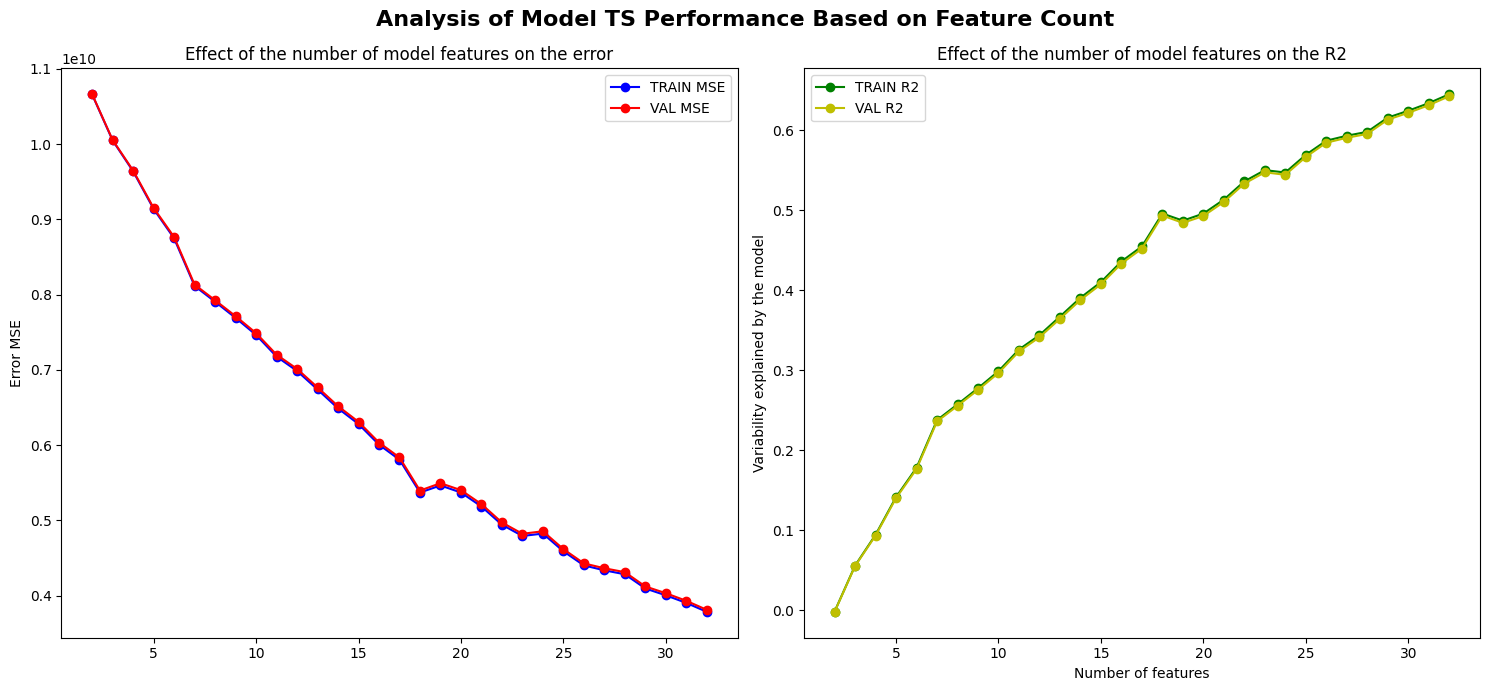

In [57]:
# Agrupar por 'Model' y 'n_features', calculando la media del MSE_train
df_grouped_TS = df_modelo_evaluacion_fit_TS.groupby(['Model', 'n_features']).mean().reset_index().sort_values('n_features',ascending=False)
fig, axs = plt.subplots(1, 2, figsize=(15, 7), sharex=True)
fig.suptitle("Analysis of Model TS Performance Based on Feature Count", fontsize=16, fontweight='bold')

# Primer subplot: MSE
axs[0].plot(df_grouped_TS['n_features'], df_grouped_TS['MSE_TRAIN'], marker='o', color='b', linestyle='-', label='TRAIN MSE')
axs[0].plot(df_grouped_TS['n_features'], df_grouped_TS['MSE_VAL'], marker='o', color='r', linestyle='-', label='VAL MSE')
axs[0].invert_xaxis()  # Invertir el eje x
axs[0].set_title("Effect of the number of model features on the error")
axs[0].legend()
axs[0].set_ylabel('Error MSE')

# Segundo subplot: R2
axs[1].plot(df_grouped_TS['n_features'], df_grouped_TS['R2_TRAIN'], marker='o', color='g', linestyle='-', label='TRAIN R2')
axs[1].plot(df_grouped_TS['n_features'], df_grouped_TS['R2_VAL'], marker='o', color='y', linestyle='-', label='VAL R2')
axs[1].invert_xaxis()  # Invertir el eje x
axs[1].set_title("Effect of the number of model features on the R2")
axs[1].legend()
axs[1].set_xlabel('Number of features')
axs[1].set_ylabel('Variability explained by the model')

# Ajustar el espacio entre subplots
plt.tight_layout()


# Mostrar los gráficos
plt.show()

## 🟢 **CONCLUSION Theil-sehn Regresion MODEL:**

In the “Effect of number of model features on error” chart we see the mean square error (MSE) for both the training and validation sets. At first, when the model only has a few features to work with, the error is quite high; meaning that the predictions are not very accurate. However, as we add more features, the error decreases for both the training and validation sets. This tells us that the model is learning better with more information. Around 25 features, the improvement starts to taper off and adding additional features does not make a huge difference to the error. The training and validation errors stay very close to each other, meaning that the model is not overfitting and is generalizing well to new data.
The “Effect of number of model features on R2” chart shows the variability that the model can explain; measured by the R² score. With few features, the R² score is close to zero, meaning that the model cannot capture useful patterns at all. But, as we increase the number of features, the R² score improves for both training and validation. After 25 features, the improvement slows down; the same way as in the MSE graph. The training and validation lines are very close, showing that the model works consistently and does not overfit.

---
## SGD Regression Analysis
- We determined that the number of variables determines the complexity of the model and the number of iterations could also determine it, however, by increasing the level of iterations we will obtain a local minimum in the long run, which increases the computational complexity, not the complexity of the model.

`````
df_modelo_evaluacion_fit_SGD=pd.DataFrame(columns=['Model','n_features','MSE_TRAIN','MSE_VAL','R2_TRAIN','R2_VAL'])
# Iterar sobre cada pliegue externo e interno en el diccionario
for fold_externo, internos in data_dict.items():
    for fold_interno, data in internos.items():      
        for combinations in combinations_dict:
            for value in combinations_dict[combinations]:
                # Separar variables cuantitativas y cualitativas
                X_train = data['Train_X'][list(value)]
                y_train = data['Train_Y']
                X_val = data['Validation_X'][list(value)]
                y_val = data['Validation_Y']
                X_test = data['Test_X'][list(value)]
                y_test = data['Test_Y']
                # Ajustar el modelo
                model = LinearRegression()
                model.fit(X_train, y_train)
                # Realizar predicciones
                y_train_pred = model.predict(X_train)
                y_val_pred = model.predict(X_val)
                # Calcular métricas
                mse_train = mean_squared_error(y_train, y_train_pred)
                mse_val = mean_squared_error(y_val, y_val_pred)
                r2_train = r2_score(y_train, y_train_pred)
                r2_val = r2_score(y_val, y_val_pred)
                # Registrar resultados
                row = pd.DataFrame([{
                    'Model': 'Linear Regression',
                    'n_features': len(value),
                    'MSE_TRAIN': mse_train,
                    'MSE_VAL': mse_val,
                    'R2_TRAIN': r2_train,
                    'R2_VAL': r2_val
                }])
                df_modelo_evaluacion_fit_SGD = pd.concat([df_modelo_evaluacion_fit_SGD, row], ignore_index=True)
df_modelo_evaluacion_fit_SGD.to_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/Regression Task2/T2.3_PREDICTION_CHARGES/df_modelo_evaluacion_fit_SGD.csv')

In [58]:
df_modelo_evaluacion_fit_SGD=pd.read_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/Regression Task2/T2.3_PREDICTION_CHARGES/df_modelo_evaluacion_fit_SGD.csv')

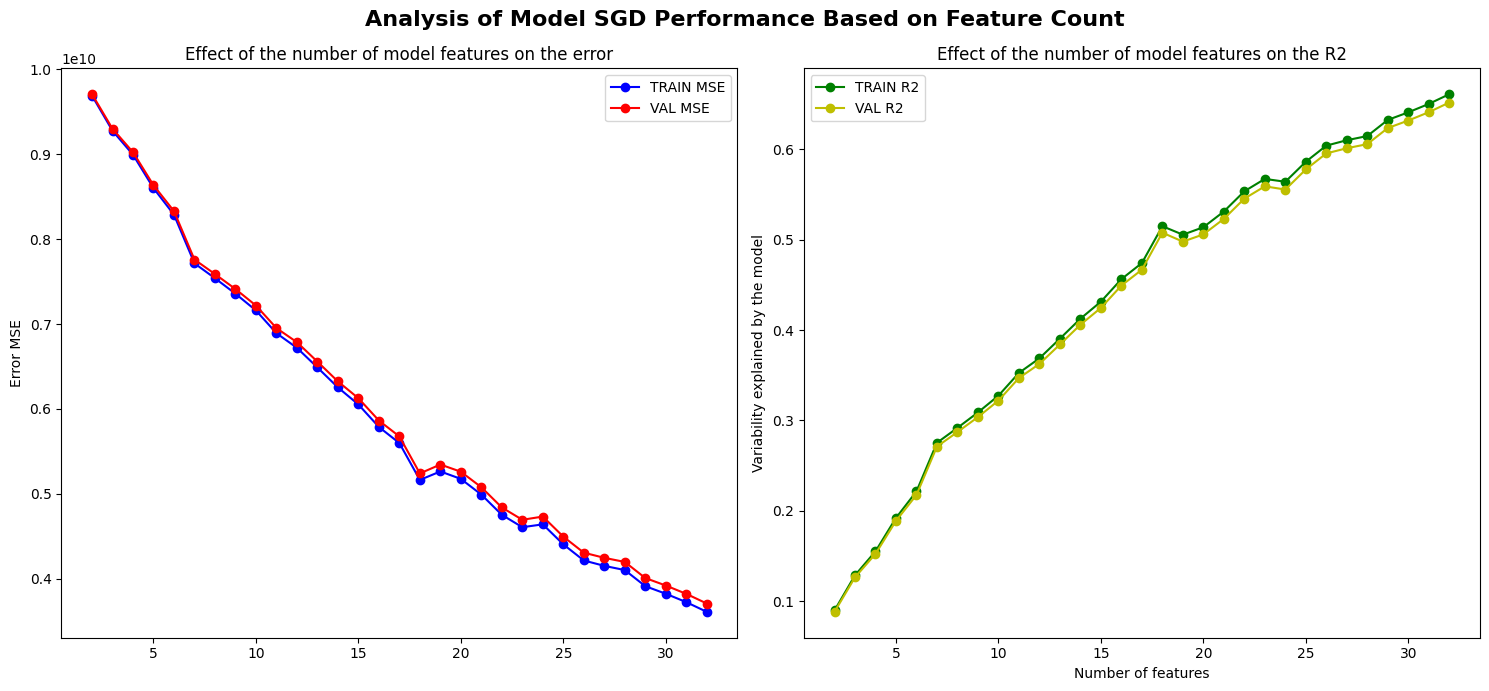

In [59]:

# Agrupar por 'Model' y 'n_features', calculando la media del MSE_train
df_grouped_SGD = df_modelo_evaluacion_fit_SGD.groupby(['Model', 'n_features']).mean().reset_index().sort_values('n_features',ascending=False)
fig, axs = plt.subplots(1, 2, figsize=(15, 7), sharex=True)
fig.suptitle("Analysis of Model SGD Performance Based on Feature Count", fontsize=16, fontweight='bold')

# Primer subplot: MSE
axs[0].plot(df_grouped_SGD['n_features'], df_grouped_SGD['MSE_TRAIN'], marker='o', color='b', linestyle='-', label='TRAIN MSE')
axs[0].plot(df_grouped_SGD['n_features'], df_grouped_SGD['MSE_VAL'], marker='o', color='r', linestyle='-', label='VAL MSE')
axs[0].invert_xaxis()  # Invertir el eje x
axs[0].set_title("Effect of the number of model features on the error")
axs[0].legend()
axs[0].set_ylabel('Error MSE')

# Segundo subplot: R2
axs[1].plot(df_grouped_SGD['n_features'], df_grouped_SGD['R2_TRAIN'], marker='o', color='g', linestyle='-', label='TRAIN R2')
axs[1].plot(df_grouped_SGD['n_features'], df_grouped_SGD['R2_VAL'], marker='o', color='y', linestyle='-', label='VAL R2')
axs[1].invert_xaxis()  # Invertir el eje x
axs[1].set_title("Effect of the number of model features on the R2")
axs[1].legend()
axs[1].set_xlabel('Number of features')
axs[1].set_ylabel('Variability explained by the model')

# Ajustar el espacio entre subplots
plt.tight_layout()


# Mostrar los gráficos
plt.show()


## 🟢 **CONCLUSION SGD Regresion MODEL:**

Considering the results of the upper graph, which analyzes the performance of the linear regression model based on Stochastic Gradient Descent (SGD) according to the number of features included in the model, we can conclude that:
In the graph on the left, the trend indicates that as the number of features increases, the error decreases for both the training and validation sets, reflecting that the model improves its fit by incorporating more information.
Besides, in the graph on the right, the coefficient of determination R² is represented on the vertical axis. Here, it shows that as the number of features increases, the R² also increases, suggesting that the model explains the variability in the data better when more features are included.
Therefore, including more features improves the model's performance, as the MSE decreases and the R² increases. Additionally, the training and validation curves are very close in both graphs, indicating that the model does not suffer from significant overfitting even as the number of features increases.


---

# Polynomial Regression Model
Observing the trends presented by the previous linear models, we have decided that the level of complexity of the model is determined by the degree of the polynomial model. Due to computational problems we were only able to calculate polynomials of degrees 2, 3, 4 and 5

`````

# Initialize an empty list to store results
results = []
i=1
# Iterar sobre cada pliegue externo e interno en el diccionario
for fold_externo, internos in data_dict.items():
    for fold_interno, data in internos.items():
        # Separar variables cuantitativas y cualitativas
        X_train = data['Train_X']
        y_train = data['Train_Y']
        X_val = data['Validation_X']
        y_val = data['Validation_Y']
        X_test = data['Test_X']
        y_test = data['Test_Y']
        
        for n_degree in range(2, 6):  
            # Ajustar el modelo
            model = Pipeline([
                ("poly_features", PolynomialFeatures(degree=n_degree, include_bias=False)),
                ("linear_regression", LinearRegression())
            ])
            model.fit(X_train, y_train)
            
            # Realizar predicciones
            y_train_pred = model.predict(X_train)
            y_val_pred = model.predict(X_val)
            
            # Calcular métricas
            mse_train = mean_squared_error(y_train, y_train_pred)
            mse_val = mean_squared_error(y_val, y_val_pred)
            r2_train = r2_score(y_train, y_train_pred)
            r2_val = r2_score(y_val, y_val_pred)
            
            # Almacenar los resultados en la lista
            results.append({
                'Model': 'Polynomial Regression',
                'Degree': n_degree,
                'MSE_TRAIN': mse_train,
                'MSE_VAL': mse_val,
                'R2_TRAIN': r2_train,
                'R2_VAL': r2_val
            })
            i=i+1
            print(i)

# Convertir la lista de resultados a un DataFrame
df_modelo_evaluacion_fit_poly = pd.DataFrame(results)

In [60]:
df_modelo_evaluacion_fit_poly=pd.read_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/Regression Task2/T2.3_PREDICTION_CHARGES/df_modelo_evaluacion_fit_poly.csv')
df_grouped_poly = df_modelo_evaluacion_fit_poly.groupby(['Model', 'Degree']).mean().reset_index().sort_values('Degree',ascending=True)
df_grouped_poly.head()

,Model,Degree,Unnamed: 0,MSE_TRAIN,MSE_VAL,R2_TRAIN,R2_VAL
0,Polynomial Regression,2,18.0,2.236607e+09,4.230951e+09,0.790155,0.602928
1,Polynomial Regression,3,19.0,1.499515e-17,1.667569e+11,1.000000,-14.661669
2,Polynomial Regression,4,20.0,2.098073e-16,2.777434e+12,1.000000,-251.681905
3,Polynomial Regression,5,21.0,7.514872e-15,1.518285e+14,1.000000,-14052.797891


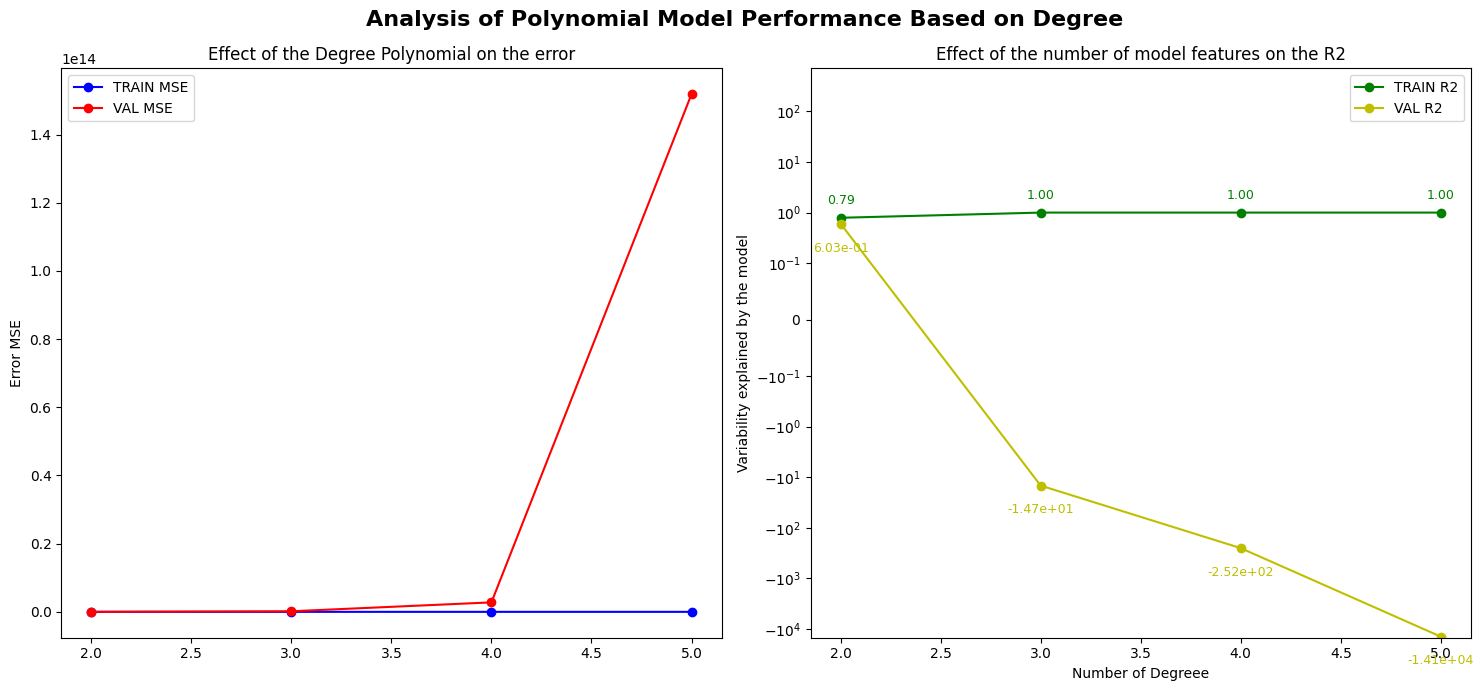

In [61]:
fig, axs = plt.subplots(1, 2, figsize=(15, 7), sharex=True)
fig.suptitle("Analysis of Polynomial Model Performance Based on Degree", fontsize=16, fontweight='bold')

# Primer subplot: MSE
axs[0].plot(df_grouped_poly['Degree'], df_grouped_poly['MSE_TRAIN'], marker='o', color='b', linestyle='-', label='TRAIN MSE')
axs[0].plot(df_grouped_poly['Degree'], df_grouped_poly['MSE_VAL'], marker='o', color='r', linestyle='-', label='VAL MSE')
axs[0].invert_xaxis()  # Invertir el eje x
axs[0].set_title("Effect of the Degree Polynomial on the error")
axs[0].legend()
axs[0].set_ylabel('Error MSE')

# Segundo subplot: R2
axs[1].plot(df_grouped_poly['Degree'], df_grouped_poly['R2_TRAIN'], marker='o', color='g', linestyle='-', label='TRAIN R2')
axs[1].plot(df_grouped_poly['Degree'], df_grouped_poly['R2_VAL'], marker='o', color='y', linestyle='-', label='VAL R2')
axs[1].invert_xaxis()  # Invertir el eje x
axs[1].set_title("Effect of the number of model features on the R2")
axs[1].legend()
axs[1].set_xlabel('Number of Degreee')
axs[1].set_ylabel('Variability explained by the model')

# Establecer escala symlog para el eje Y
axs[1].set_yscale('symlog', linthresh=1e-1)  # linthresh ajusta el umbral para escala logarítmica

# Añadir valores en cada punto para TRAIN R2
for x_val, y_val in zip(df_grouped_poly['Degree'], df_grouped_poly['R2_TRAIN']):
    axs[1].annotate(f"{y_val:.2f}", 
                    xy=(x_val, y_val), 
                    xytext=(0, 10),  # Ajuste de posición vertical
                    textcoords="offset points", 
                    ha='center', 
                    fontsize=9, 
                    color='g')

# Añadir valores en cada punto para VAL R2
for x_val, y_val in zip(df_grouped_poly['Degree'], df_grouped_poly['R2_VAL']):
    axs[1].annotate(f"{y_val:.2e}",  # Formato científico para valores negativos grandes
                    xy=(x_val, y_val), 
                    xytext=(0, -20),  # Ajuste de posición vertical para valores negativos
                    textcoords="offset points", 
                    ha='center', 
                    fontsize=9, 
                    color='y')

# Ajustar el espacio entre subplots
plt.tight_layout()

# Mostrar los gráficos
plt.show()



## 🟢 **CONCLUSION POLYNOMIAL MODEL:**

The plots reveal a clear **overfitting** problem in the polynomial model tested. Starting at degree 3, the **Mean Squared Error (MSE)** on the training set drops dramatically, suggesting that the model is memorizing the data rather than learning general patterns. However, this apparent benefit on the training set translates into a significant increase in **MSE** on the validation set, indicating an inability of the model to generalize adequately.

The analysis of the coefficient of determination (\(R^2\)) supports this assessment. On the training set, the model achieves an \(R^2 = 1\), implying a perfect fit. However, on the validation set, the \(R^2\) rapidly deteriorates and becomes negative starting at degree 3. A negative \(R^2\) indicates that the model is less effective than a trivial prediction based on the mean of the data.

### Best polynomial degree identified
Of the degrees evaluated, **degree 2** achieves the most balanced performance between the training and validation sets. Although not perfect, this model achieves an \(R^2 \approx 0.6\) in validation and a low MSE on this set, suggesting that it could be useful in practical applications.

### Possible causes of overfitting
1. **Lack of regularization:** The absence of strategies to control model complexity encourages overfitting to the training data.

2. **Inadequate model:** Polynomials may not be the best choice for this dataset. Alternatives such as non-linear or machine learning-based models could better fit the structure of the data.

### Recommendations
Degree 2 represents a viable option for this case, but the underlying problem could be solved by exploring:
- **Regularization methods**, such as polynomial regression with penalties (Ridge or Lasso).
- **Alternative models**, such as decision trees, SVMs or neural networks, could capture more complex patterns without overfitting.

In conclusion, although degree 2 offers a reasonable balance, a more comprehensive strategy should consider both regularization and the exploration of models more appropriate to the nature of the problem.

---
# No Linear Models:

---
### Nearest Neighbor Regression:
- The complexity of these models is determined by the number of neighbors considered by the KNN regressor.


````
# Initialize an empty list to store results
results = []
i=1
# Iterar sobre cada pliegue externo e interno en el diccionario
for fold_externo, internos in data_dict.items():
    for fold_interno, data in internos.items():
        # Separar variables cuantitativas y cualitativas
        X_train = data['Train_X']
        y_train = data['Train_Y']
        X_val = data['Validation_X']
        y_val = data['Validation_Y']
        X_test = data['Test_X']
        y_test = data['Test_Y']
        
        for neighbors in range(2, 202):  
            # Ajustar el modelo
            model =  KNeighborsRegressor(n_neighbors=neighbors)
            model.fit(X_train, y_train)
            
            # Realizar predicciones
            y_train_pred = model.predict(X_train)
            y_val_pred = model.predict(X_val)
            
            # Calcular métricas
            mse_train = mean_squared_error(y_train, y_train_pred)
            mse_val = mean_squared_error(y_val, y_val_pred)
            r2_train = r2_score(y_train, y_train_pred)
            r2_val = r2_score(y_val, y_val_pred)
            
            # Almacenar los resultados en la lista
            results.append({
                'Model': 'Polynomial Regression',
                'Neighbors': neighbors,
                'MSE_TRAIN': mse_train,
                'MSE_VAL': mse_val,
                'R2_TRAIN': r2_train,
                'R2_VAL': r2_val
            })
            i=i+1
            print(i)

# Convertir la lista de resultados a un DataFrame
df_modelo_evaluacion_fit_KNN = pd.DataFrame(results)

In [62]:
df_modelo_evaluacion_fit_KNN=pd.read_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/Regression Task2/T2.3_PREDICTION_CHARGES/df_modelo_evaluacion_fit_KNN.csv')
df_modelo_evaluacion_fit_KNN

,Unnamed: 0,Model,Neighbors,MSE_TRAIN,MSE_VAL,R2_TRAIN,R2_VAL
0,0,Polynomial Regression,2,2.110783e+09,6.012241e+09,0.809224,0.435546
1,1,Polynomial Regression,3,2.853086e+09,5.626252e+09,0.742133,0.471784
2,2,Polynomial Regression,4,3.472886e+09,5.523976e+09,0.686115,0.481386
3,3,Polynomial Regression,5,3.778409e+09,5.424189e+09,0.658501,0.490755
4,4,Polynomial Regression,6,4.015442e+09,5.410798e+09,0.637078,0.492012
...,...,...,...,...,...,...,...
1995,1995,Polynomial Regression,197,6.930272e+09,7.120264e+09,0.357886,0.338809
1996,1996,Polynomial Regression,198,6.935967e+09,7.125703e+09,0.357359,0.338303
1997,1997,Polynomial Regression,199,6.939822e+09,7.128852e+09,0.357002,0.338011
1998,1998,Polynomial Regression,200,6.946196e+09,7.132894e+09,0.356411,0.337636


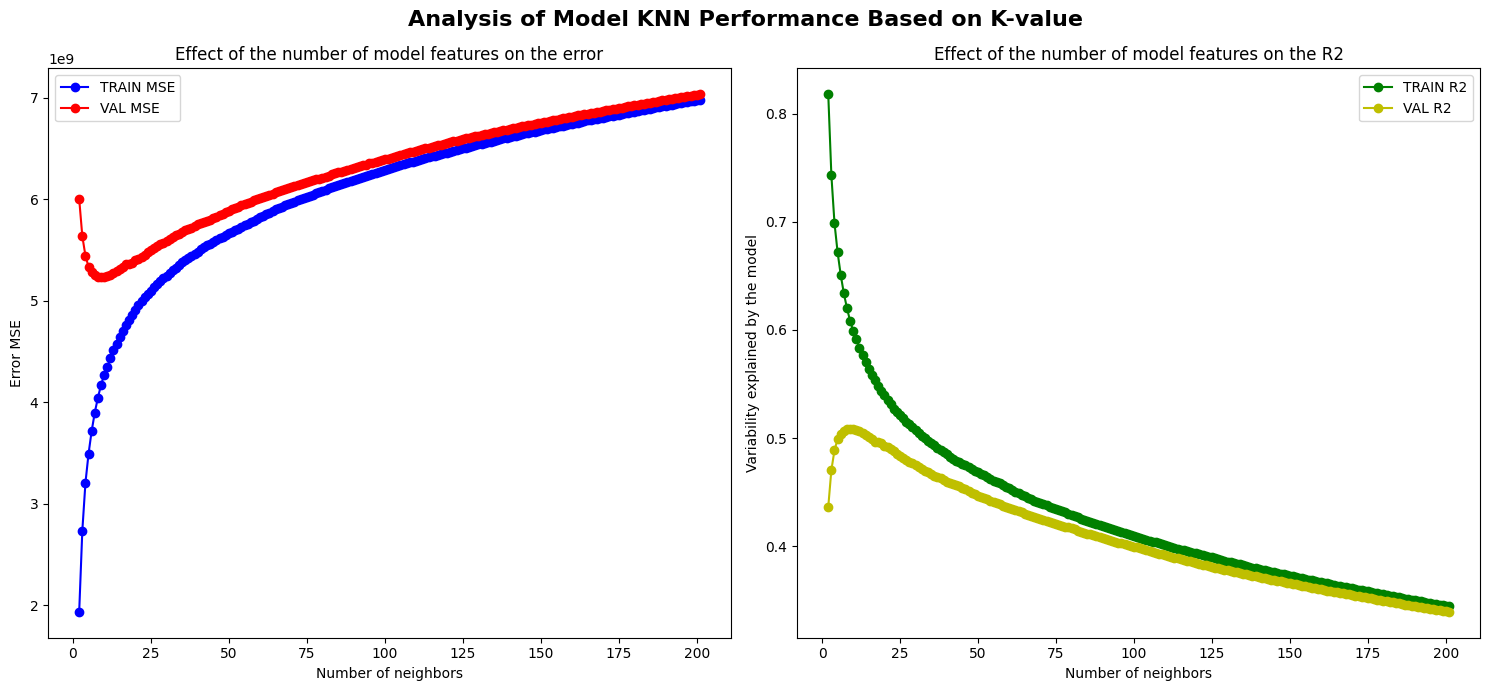

In [63]:
df_grouped_KNN = df_modelo_evaluacion_fit_KNN.groupby(['Model', 'Neighbors']).mean().reset_index().sort_values('Neighbors',ascending=False)
fig, axs = plt.subplots(1, 2, figsize=(15, 7), sharex=True)
fig.suptitle("Analysis of Model KNN Performance Based on K-value", fontsize=16, fontweight='bold')

# Primer subplot: MSE
axs[0].plot(df_grouped_KNN['Neighbors'], df_grouped_KNN['MSE_TRAIN'], marker='o', color='b', linestyle='-', label='TRAIN MSE')
axs[0].plot(df_grouped_KNN['Neighbors'], df_grouped_KNN['MSE_VAL'], marker='o', color='r', linestyle='-', label='VAL MSE')
axs[0].invert_xaxis()  # Invertir el eje x
axs[0].set_title("Effect of the number of model features on the error")
axs[0].set_xlabel('Number of neighbors')
axs[0].legend()
axs[0].set_ylabel('Error MSE')

# Segundo subplot: R2
axs[1].plot(df_grouped_KNN['Neighbors'], df_grouped_KNN['R2_TRAIN'], marker='o', color='g', linestyle='-', label='TRAIN R2')
axs[1].plot(df_grouped_KNN['Neighbors'], df_grouped_KNN['R2_VAL'], marker='o', color='y', linestyle='-', label='VAL R2')
axs[1].invert_xaxis()  # Invertir el eje x
axs[1].set_title("Effect of the number of model features on the R2")
axs[1].legend()
axs[1].set_xlabel('Number of neighbors')
axs[1].set_ylabel('Variability explained by the model')

# Ajustar el espacio entre subplots
plt.tight_layout()


# Mostrar los gráficos
plt.show()


## 🟢 **CONCLUSION KNN REGRESSOR MODEL:**

The performance of the K-Nearest Neighbors (KNN) model is evaluated using the “Mean Square Error (MSE)” and the “Coefficient of Determination (R^2)”.

The MSE is shown on the y-axis for both the training and validation datasets. As the number of neighbors increases, we can see how the training MSE decreases, which is due to the model getting a better fit to the training data. However, at first the Val MSE decreases and then starts to increase slightly, suggesting that at a certain point, adding more neighbors introduces noise and reduces the model’s ability to generalize. This behavior shows a transition from underfitting to overfitting.

On the other hand, we show the R^2, which complements the MSE analysis. The training R^2 line increases with the number of features, reflecting how the model has improved the ability to explain the variance in the training data. However, the R^2 Val line increases until it reaches a peak and then starts to decrease. This indicates that while the model performs well on the training data, on unseen validation data it does not continue to improve after a certain point. The gap between R^2 Train and R^2 Val widens as the number of features increases, providing evidence of overfitting.

In conclusion, the graphs show how adding more features initially improves the model's performance, but after a certain point, it starts to overfit. This is seen when the validation MSE stops decreasing and starts increasing, while the validation R^2 peaks and then decreases. The model is focusing too much on the training data, capturing noise instead of useful patterns, so it is important to find the right balance in the number of features used.

---
### Decision Tree Regression


````
# Initialize an empty list to store results
results = []
# Iterar sobre cada pliegue externo e interno en el diccionario
for fold_externo, internos in data_dict.items():
    for fold_interno, data in internos.items():
        # Separar variables cuantitativas y cualitativas
        X_train = data['Train_X']
        y_train = data['Train_Y']
        X_val = data['Validation_X']
        y_val = data['Validation_Y']
        X_test = data['Test_X']
        y_test = data['Test_Y']
        # Iterar sobre todas las combinaciones de características
        for max_depth_value in range(1, 41):
            for min_samples_leaf_value in [100, 200, 300, 400, 500, 600, 700, 800, 900, 1000, 1100, 1200, 1300, 1400, 1500, 1600, 1700, 1800, 1900, 2000]:
                # Ajustar el modelo
                model =  DecisionTreeRegressor(max_depth=max_depth_value,min_samples_leaf=min_samples_leaf_value,random_state=42)
                model.fit(X_train, y_train)
                
                # Realizar predicciones
                y_train_pred = model.predict(X_train)
                y_val_pred = model.predict(X_val)
                
                # Calcular métricas
                mse_train = mean_squared_error(y_train, y_train_pred)
                mse_val = mean_squared_error(y_val, y_val_pred)
                r2_train = r2_score(y_train, y_train_pred)
                r2_val = r2_score(y_val, y_val_pred)
                
                # Almacenar los resultados en la lista
                results.append({
                    'Model': 'Decision Tree',
                    'Depth_value': max_depth_value,
                    'min_samples_leaf_value': min_samples_leaf_value,
                    'MSE_TRAIN': mse_train,
                    'MSE_VAL': mse_val,
                    'R2_TRAIN': r2_train,
                    'R2_VAL': r2_val
                })
                i=i+1
                print(i)

# Convertir la lista de resultados a un DataFrame
df_modelo_evaluacion_fit_DT = pd.DataFrame(results)
df_modelo_evaluacion_fit_DT.to_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/Regression Task2/T2.3_PREDICTION_CHARGES/df_modelo_evaluacion_fit_DT.csv', index=False)

In [64]:
df_modelo_evaluacion_fit_DT= pd.read_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/Regression Task2/T2.3_PREDICTION_CHARGES/df_modelo_evaluacion_fit_DT.csv')
df_modelo_evaluacion_fit_DT


,Model,Depth_value,min_samples_leaf_value,MSE_TRAIN,MSE_VAL,R2_TRAIN,R2_VAL
0,Decision Tree,1,100,6.651033e+09,6.757857e+09,3.988689e-01,0.365544
1,Decision Tree,1,200,6.651033e+09,6.757857e+09,3.988689e-01,0.365544
2,Decision Tree,1,300,6.713753e+09,6.766662e+09,3.932000e-01,0.364718
3,Decision Tree,1,400,6.912767e+09,6.763129e+09,3.752129e-01,0.365049
4,Decision Tree,1,500,7.136335e+09,6.898608e+09,3.550065e-01,0.352330
...,...,...,...,...,...,...,...
7995,Decision Tree,40,1600,8.158102e+09,8.280222e+09,2.441237e-01,0.231094
7996,Decision Tree,40,1700,8.340820e+09,8.467307e+09,2.271942e-01,0.213721
7997,Decision Tree,40,1800,1.079291e+10,1.076904e+10,2.220446e-16,-0.000019
7998,Decision Tree,40,1900,1.079291e+10,1.076904e+10,2.220446e-16,-0.000019


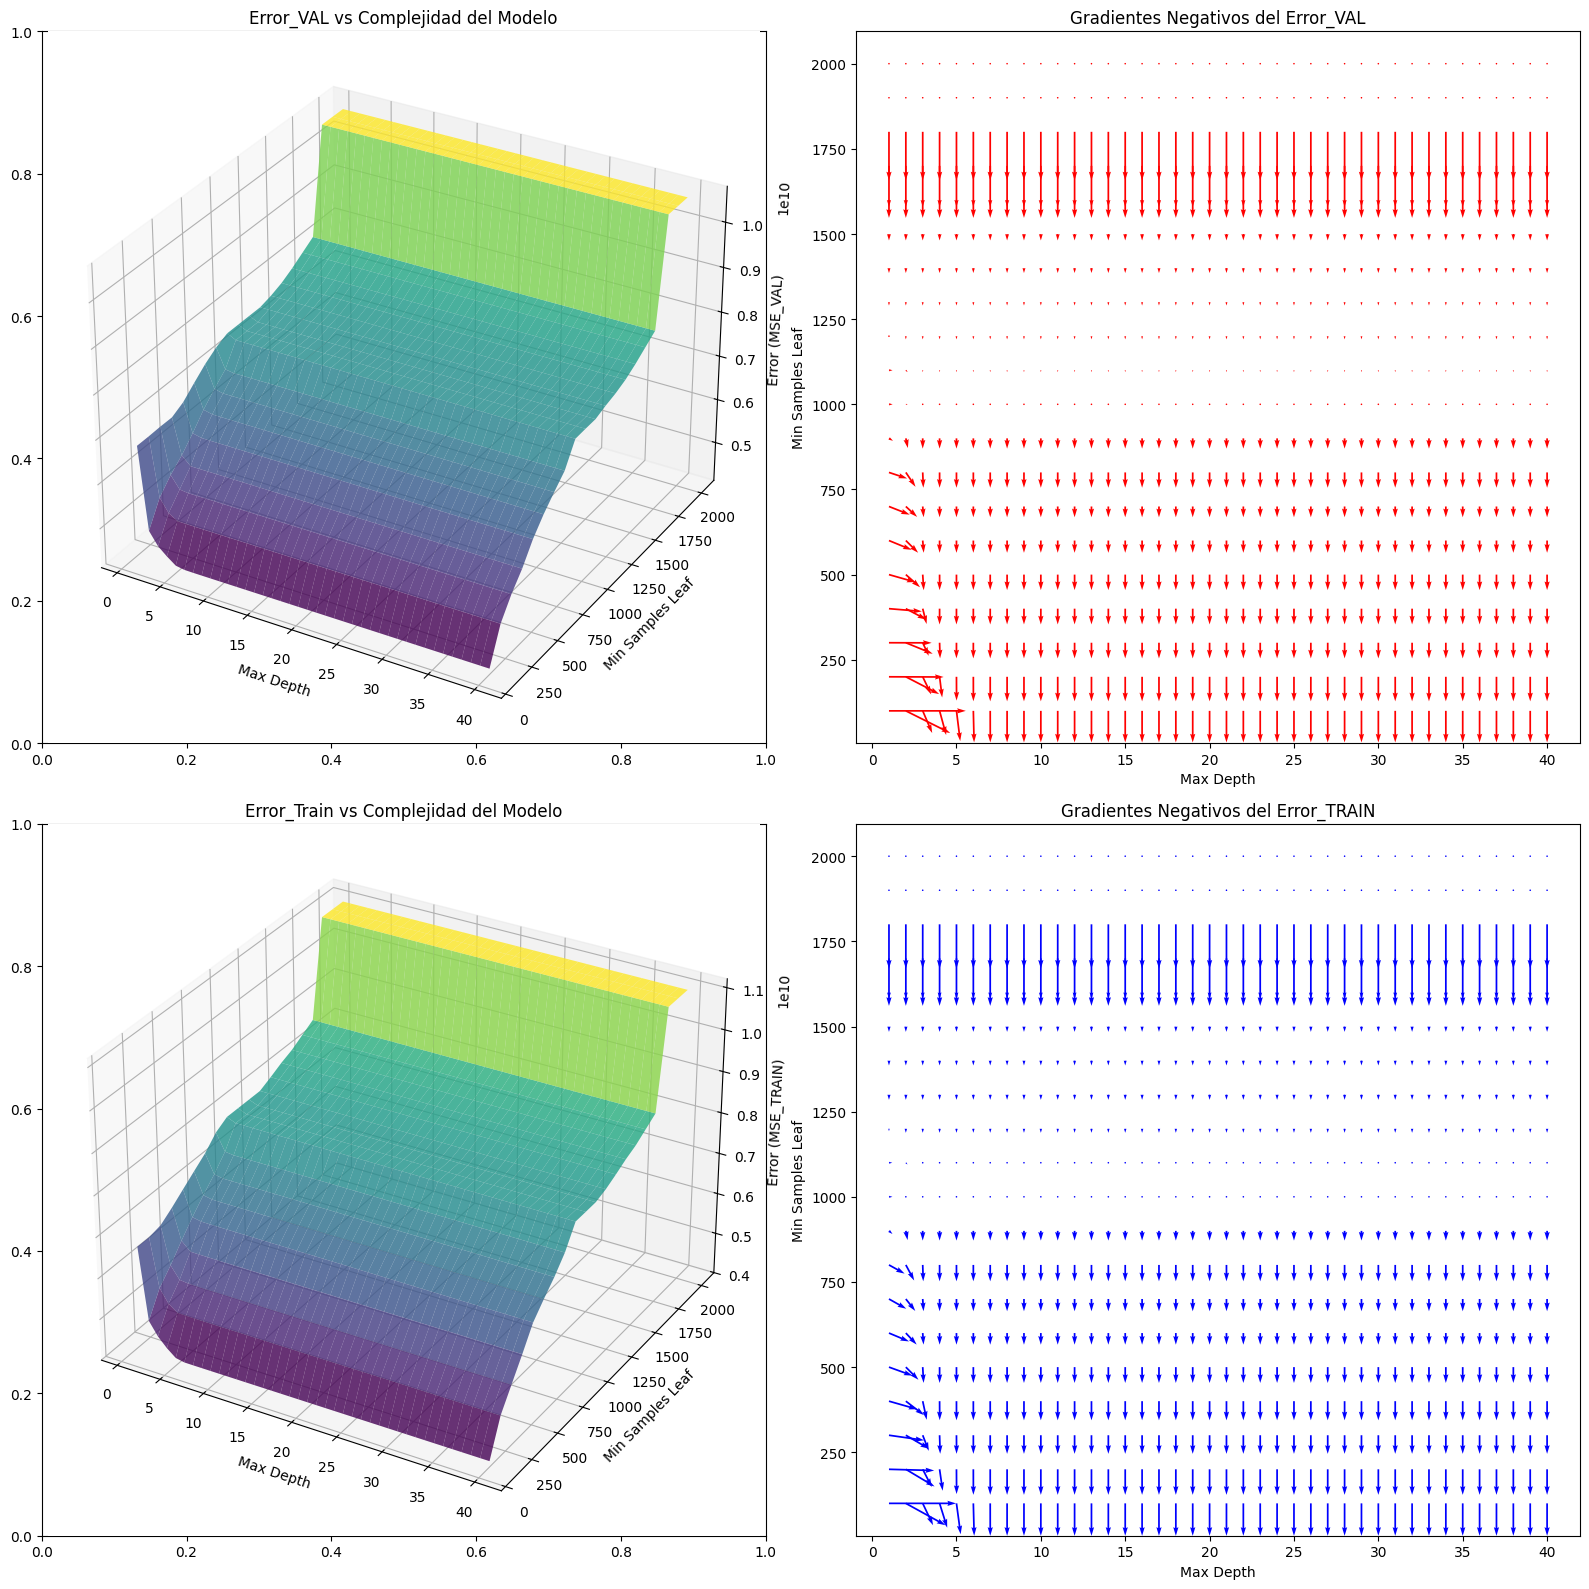

Diferencia en el gradiente en max_depth : 269372041.9517488
Diferencia en el gradiente en min_samples_leaf : 1395474315.3617601
Diferencia en los valores Z: 10196107466.930094
Correlación de Pearson: 0.9982653310955681


In [65]:
errors_val = df_modelo_evaluacion_fit_DT.drop_duplicates(subset=['Depth_value', 'min_samples_leaf_value']).pivot_table(index='Depth_value', columns='min_samples_leaf_value', values='MSE_VAL', aggfunc='mean').values
errors_train = df_modelo_evaluacion_fit_DT.drop_duplicates(subset=['Depth_value', 'min_samples_leaf_value']).pivot_table(index='Depth_value', columns='min_samples_leaf_value', values='MSE_TRAIN', aggfunc='mean').values

# Definir valores de los ejes
max_depths = df_modelo_evaluacion_fit_DT['Depth_value'].unique()
min_samples_leafs = df_modelo_evaluacion_fit_DT['min_samples_leaf_value'].unique()

# Calcular gradientes
grad_max_depth_val, grad_min_samples_leaf_val = np.gradient(errors_val)
grad_max_depth_train, grad_min_samples_leaf_train = np.gradient(errors_train)

# Invertir los gradientes para obtener los gradientes negativos
grad_max_depth_neg_val = -grad_max_depth_val
grad_min_samples_leaf_neg_val = -grad_min_samples_leaf_val

grad_max_depth_neg_train = -grad_max_depth_train
grad_min_samples_leaf_neg_train = -grad_min_samples_leaf_train

# Create a figure with 2 rows and 2 columns
fig, axes = plt.subplots(2, 2, figsize=(16, 16))

# Primer gráfico: Visualizar espacio 3D VAL
ax1 = axes[0, 0]  
X, Y = np.meshgrid(max_depths, min_samples_leafs)
ax1 = fig.add_subplot(221, projection='3d')  
ax1.plot_surface(X, Y, errors_val.T, cmap='viridis', alpha=0.8)
ax1.set_xlabel('Max Depth')
ax1.set_ylabel('Min Samples Leaf')
ax1.set_zlabel('Error (MSE_VAL)')
ax1.set_title('Error_VAL vs Complejidad del Modelo')

# Segundo gráfico: Visualizar gradientes negativos VAL
ax2 = axes[0, 1]  # Segundo subgráfico
ax2.quiver(max_depths, min_samples_leafs, grad_max_depth_neg_val.T, grad_min_samples_leaf_neg_val.T, color='r')
ax2.set_xlabel('Max Depth')
ax2.set_ylabel('Min Samples Leaf')
ax2.set_title('Gradientes Negativos del Error_VAL')

# Tercer gráfico: Visualizar espacio 3D TRAIN
ax3 = axes[1, 0] 
ax3 = fig.add_subplot(223, projection='3d')  
ax3.plot_surface(X, Y, errors_train.T, cmap='viridis', alpha=0.8)
ax3.set_xlabel('Max Depth')
ax3.set_ylabel('Min Samples Leaf')
ax3.set_zlabel('Error (MSE_TRAIN)')
ax3.set_title('Error_Train vs Complejidad del Modelo')

# Cuarto gráfico: Visualizar gradientes negativos TRAIN
ax4 = axes[1, 1]  
ax4.quiver(max_depths, min_samples_leafs, grad_max_depth_neg_train.T, grad_min_samples_leaf_neg_train.T, color='b')
ax4.set_xlabel('Max Depth')
ax4.set_ylabel('Min Samples Leaf')
ax4.set_title('Gradientes Negativos del Error_TRAIN')

# Ajustar el espacio entre subgráficos
plt.tight_layout()
plt.show()


# Comparar las diferencias en los gradientes
diff_grad_Depth = np.linalg.norm(grad_max_depth_train - grad_max_depth_val)
diff_grad_Leaf = np.linalg.norm(grad_min_samples_leaf_train - grad_min_samples_leaf_val)

print(f"Diferencia en el gradiente en max_depth : {diff_grad_Depth}")
print(f"Diferencia en el gradiente en min_samples_leaf : {diff_grad_Leaf}")

# Comparar las diferencias en los valores Z
diff_Z = np.linalg.norm( errors_train - errors_val)
print(f"Diferencia en los valores Z: {diff_Z}")

# Aplanar las matrices en un solo vector
errors_train_flat = errors_train.flatten()
errors_val_flat = errors_val.flatten()

# Calcular la correlación de Pearson
correlacion, _ = pearsonr(errors_train_flat, errors_val_flat)
print(f"Correlación de Pearson: {correlacion}")


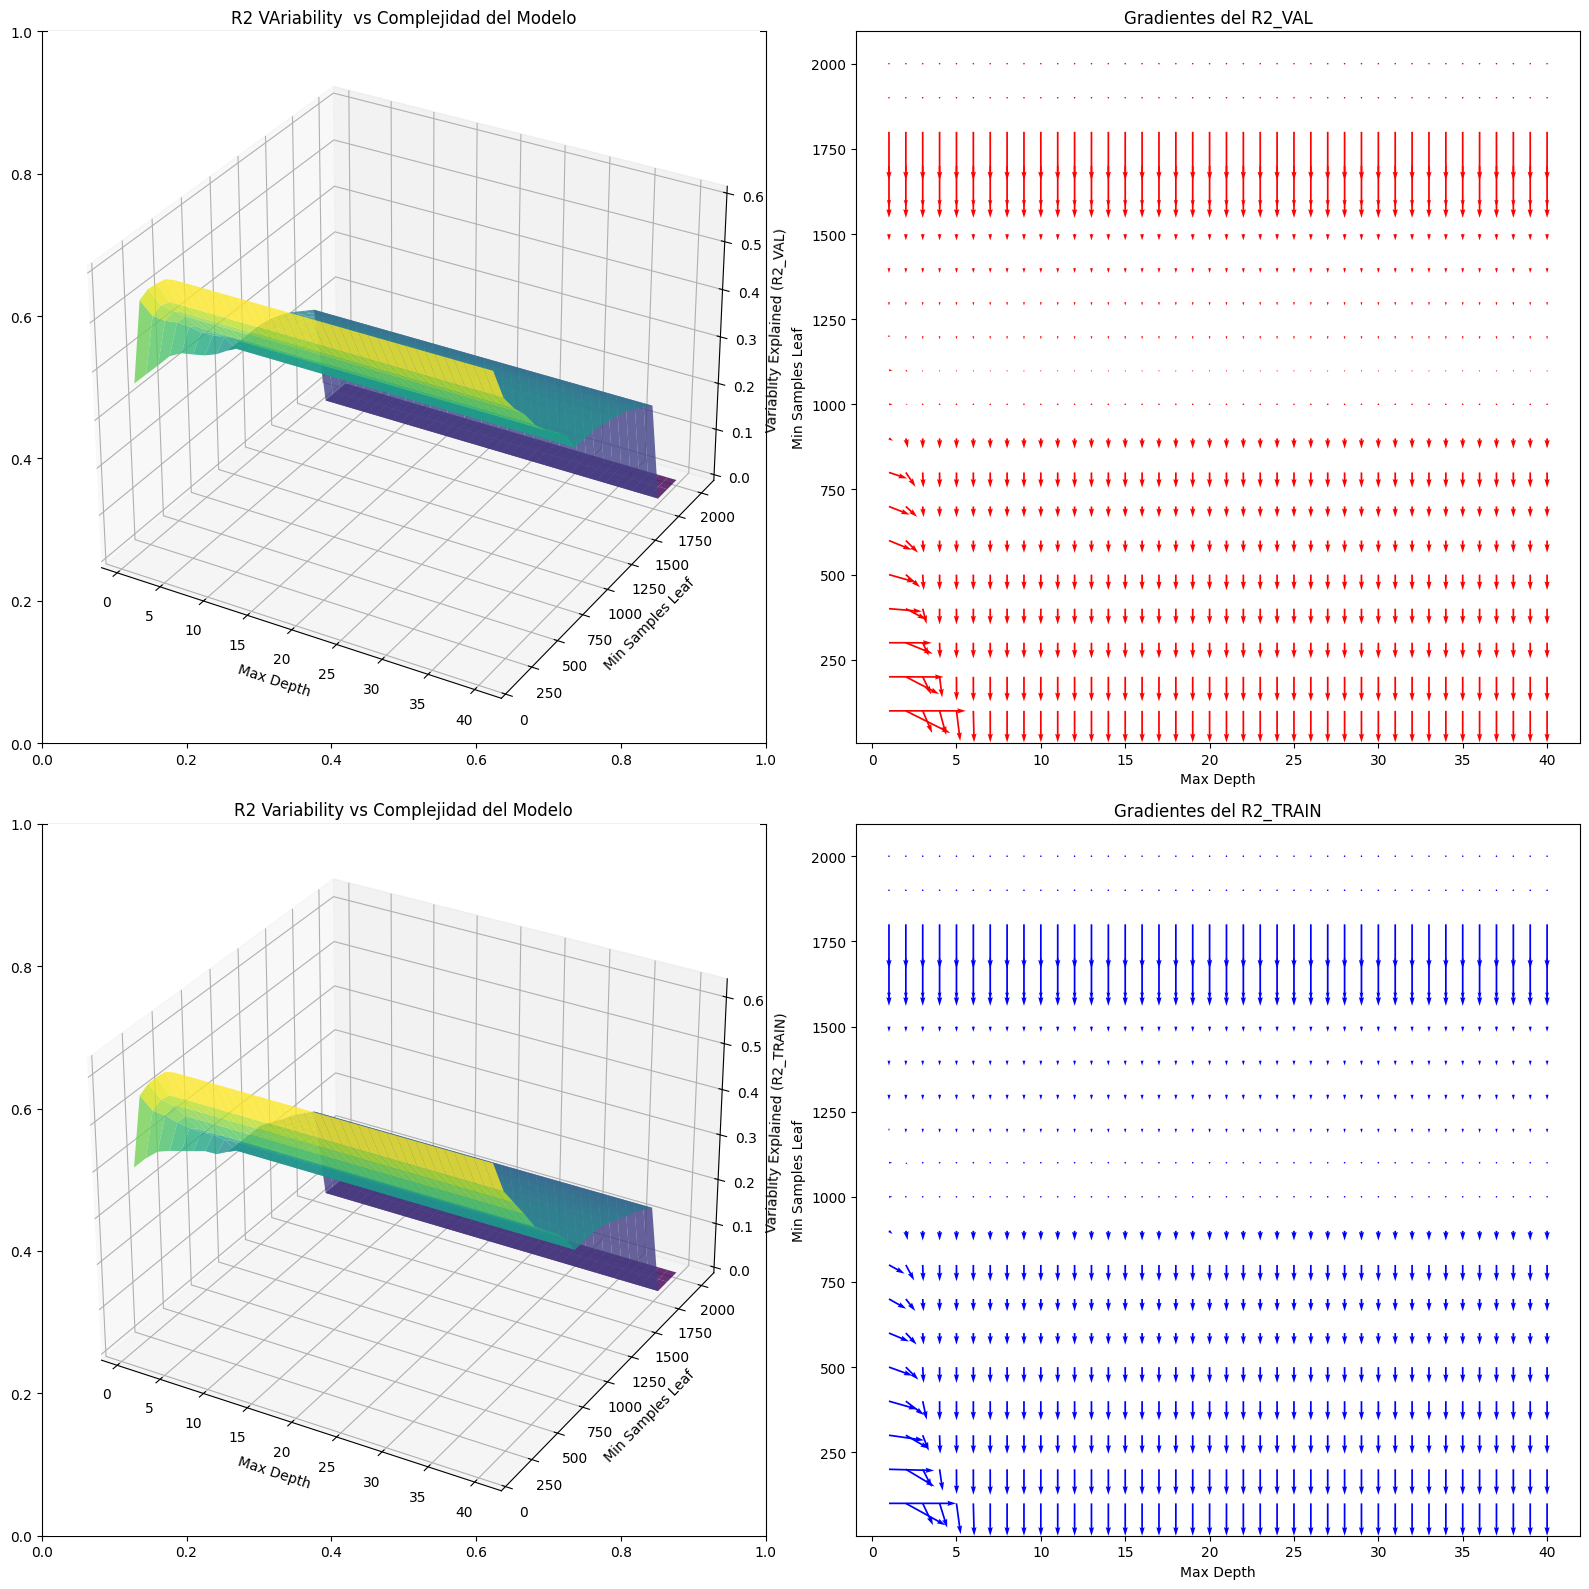

Diferencia en el gradiente en max_depth : 0.03502851189158602
Diferencia en el gradiente en min_samples_leaf : 0.11702758200166381
Diferencia en los valores Z: 0.3263291426551508


In [66]:
R2_val = df_modelo_evaluacion_fit_DT.drop_duplicates(subset=['Depth_value', 'min_samples_leaf_value']).pivot_table(index='Depth_value', columns='min_samples_leaf_value', values='R2_VAL', aggfunc='mean').values
R2_train = df_modelo_evaluacion_fit_DT.drop_duplicates(subset=['Depth_value', 'min_samples_leaf_value']).pivot_table(index='Depth_value', columns='min_samples_leaf_value', values='R2_TRAIN', aggfunc='mean').values

# Definir valores de los ejes
max_depths = df_modelo_evaluacion_fit_DT['Depth_value'].unique()
min_samples_leafs = df_modelo_evaluacion_fit_DT['min_samples_leaf_value'].unique()

# Calcular gradientes
grad_max_depth_val, grad_min_samples_leaf_val = np.gradient(R2_val)
grad_max_depth_train, grad_min_samples_leaf_train = np.gradient(R2_train)


fig, axes = plt.subplots(2, 2, figsize=(16, 16))

# Primer gráfico: Visualizar espacio 3D VAL
ax1 = axes[0, 0]  
X, Y = np.meshgrid(max_depths, min_samples_leafs)
ax1 = fig.add_subplot(221, projection='3d')  
ax1.plot_surface(X, Y, R2_val.T, cmap='viridis', alpha=0.8)
ax1.set_xlabel('Max Depth')
ax1.set_ylabel('Min Samples Leaf')
ax1.set_zlabel('Variablity Explained (R2_VAL)')
ax1.set_title('R2 VAriability  vs Complejidad del Modelo')

# Segundo gráfico: Visualizar gradientes  VAL
ax2 = axes[0, 1]  
ax2.quiver(max_depths, min_samples_leafs, grad_max_depth_val.T, grad_min_samples_leaf_val.T, color='r')
ax2.set_xlabel('Max Depth')
ax2.set_ylabel('Min Samples Leaf')
ax2.set_title('Gradientes del R2_VAL')

# Tercer gráfico: Visualizar espacio 3D TRAIN
ax3 = axes[1, 0]  
ax3 = fig.add_subplot(223, projection='3d')  # Corrected subplot position
ax3.plot_surface(X, Y, R2_train.T, cmap='viridis', alpha=0.8)
ax3.set_xlabel('Max Depth')
ax3.set_ylabel('Min Samples Leaf')
ax3.set_zlabel('Variablity Explained (R2_TRAIN)')
ax3.set_title('R2 Variability vs Complejidad del Modelo')

# Cuarto gráfico: Visualizar gradientes TRAIN
ax4 = axes[1, 1]  # Segundo subgráfico de la segunda fila
ax4.quiver(max_depths, min_samples_leafs, grad_max_depth_train.T, grad_min_samples_leaf_train.T, color='b')
ax4.set_xlabel('Max Depth')
ax4.set_ylabel('Min Samples Leaf')
ax4.set_title('Gradientes del R2_TRAIN')

# Ajustar el espacio entre subplots
plt.tight_layout()
plt.show()

# Comparar las diferencias en los gradientes
diff_grad_Depth = np.linalg.norm(grad_max_depth_train - grad_max_depth_val)
diff_grad_Leaf = np.linalg.norm(grad_min_samples_leaf_train - grad_min_samples_leaf_val)

print(f"Diferencia en el gradiente en max_depth : {diff_grad_Depth}")
print(f"Diferencia en el gradiente en min_samples_leaf : {diff_grad_Leaf}")

# Comparar las diferencias en los valores Z
diff_Z = np.linalg.norm( R2_val - R2_train)
print(f"Diferencia en los valores Z: {diff_Z}")




## 🟢 **CONCLUSION DECISION TREE MODEL:**

### **Model Complexity Impact Analysis**:

By evaluating the impact of the parameters **max_depth** (maximum tree depth) and **min_samples_leaf** (minimum number of samples in each leaf) on both **error** and **explained variability (R²)**, important conclusions can be drawn.


### **1. Error Results**
In the graphs above, which show the relationship between error and model complexity, the effects of **max_depth** and **min_samples_leaf** were analyzed:

- The **difference in gradient** with respect to **max_depth** is **269 million**, while for **min_samples_leaf** it is significantly higher, reaching **1.395 million**. This indicates that **min_samples_leaf** has a greater influence on reducing error than tree depth. - Furthermore, the **difference in Z values** is extremely high, with a value of **10.196 million**, which reinforces that the error varies drastically as the model complexity increases. This behavior reflects a clear tendency to **overfit** when the parameters are not adequately controlled.
- On the other hand, the **Pearson correlation** is **0.9983**, which shows a **very strong and positive linear relationship** between the model complexity and the validation error. That is, as the complexity increases (particularly **max_depth**), the validation error increases, suggesting a loss of generalization.

**Partial conclusion**:
The parameter **min_samples_leaf** is more effective than **max_depth** in controlling the error and reducing overfitting. Increasing **max_depth** without limits can decrease the training error, but at the cost of a significant increase in the validation error.


### **2. Results on Explained Variability (R²)**
In the graphs below, which show how **R²** varies with model complexity, the following results were obtained:

- The **difference in the gradient** is smaller than in the case of the error:
- For **max_depth**, it is **0.035**, while for **min_samples_leaf** it reaches **0.117**. Although these values ​​are small, it is again observed that **min_samples_leaf** has a greater impact.
- The **difference in the Z values** of **0.3263** reflects that, as the complexity of the model increases, the variability explained in validation decreases. This indicates that the model loses its ability to generalize, another indication of **overfitting**.
- Although **max_depth** can initially improve **R²**, excessive depth ends up reducing the variability explained in validation. Training performance remains high, but at the cost of a deterioration in validation.

**Partial Conclusion**:
The parameter **min_samples_leaf** is still more relevant than **max_depth** in improving **R²** and avoiding loss of generalization. Controlling **max_depth** is crucial, as its excess deteriorates the model performance in validation.


### **Final Conclusion**
The results indicate that **min_samples_leaf** has a greater impact than **max_depth** in both reducing error and improving explained variability (**R²**). This occurs because **min_samples_leaf** limits the complexity of the tree by avoiding excessive splits into leaves with few samples, which reduces the risk of **overfitting**.

In contrast, **max_depth**, if not limited, leads to an increase in model complexity that generates **overfitting**:
- Error decreases in training, but increases significantly in validation.
- Explained variability (**R²**) in validation deteriorates, affecting the model's ability to generalize.

To build a robust and balanced model, it is recommended to:
1. **Limit the maximum depth of the model (max_depth)** to avoid overfitting.
2. **Adjust min_samples_leaf** appropriately, since it is the parameter with the greatest influence on overall performance.

In this way, it is possible to obtain a model with a **good fit** and a **greater generalization capacity**, optimizing performance in both training and validation.

---
# NEURONAL NETWORK USING KERAS FOR FORECASTING CHARGES FEATURE

In this code, a neural network model is trained and evaluated for different data partitions (outer and inner folds). First, training, validation and test sets are obtained for each fold. Then, a sequential Keras model is built with several dense layers and ReLU activation. The model is compiled with the Adam optimizer and the MSE loss function. Next, the model is trained on the training set and predictions are generated for both training and validation. Finally, performance metrics (MAE, MAPE, RMSE, R² and adjusted R²) are calculated and the results are saved in a DataFrame, to be analyzed later with the other evaluated models.

In [67]:
results=[]
for fold_externo, internos in data_dict.items():
    for fold_interno, data in internos.items():
        print(f"Fold Externo: {fold_externo}, Fold Interno: {fold_interno}")
        
        # Separar variables
        X_train = data['Train_X'].values
        y_train = data['Train_Y'].values
        X_val = data['Validation_X'].values
        y_val = data['Validation_Y'].values
        X_test = data['Test_X'].values
        y_test = data['Test_Y'].values

        model = Sequential([
        Input(shape=(32,)),
        Dense(64, activation='relu'),
        Dense(32, activation='relu'),
        Dense(16, activation='relu'),
        Dense(1)])

        # Compilar el modelo
        model.compile(optimizer='adam', loss='mse', metrics=['mae'])# configura cómo se entrenara el modelo

        # Entrenar el modelo
        model.fit(X_train, y_train, epochs=100, batch_size=32, verbose=0)

        # Obtener las predicciones
        y_train_pred = model.predict(X_train)
        y_val_pred = model.predict(X_val)

        # Calcular métricas
        n_train, p_train = X_train.shape
        mae_train, mape_train, rmse_train, r2_train, r2_adj_train = evaluate_model(y_train, y_train_pred, n_train, p_train)
        
        n_val, p_val = X_val.shape
        mae_val, mape_val, rmse_val, r2_val, r2_adj_val = evaluate_model(y_val, y_val_pred, n_val, p_val)

        # Guardar resultados
        results.append({
            'Fold_Externo': fold_externo,
            'Fold_Interno': fold_interno,
            'Model': 'Neural Network',
            'MAE_VAL': mae_val,
            'MAPE_VAL': mape_val,
            'RMSE_VAL': rmse_val,
            'R2_VAL': r2_val,
            'R2_adjusted_VAL': r2_adj_val,
            'MAE_TRAIN': mae_train,
            'MAPE_TRAIN': mape_train,
            'RMSE_TRAIN': rmse_train,
            'R2_TRAIN': r2_train,
            'R2_adjusted_TRAIN': r2_adj_train
        })

# Convertir a DataFrame
df_evaluation_red_neuronal = pd.DataFrame(results).set_index(['Fold_Externo', 'Fold_Interno'])


Fold Externo: Fold_Externo_0, Fold Interno: Fold_Interno_1
111/111 ━━━━━━━━━━━━━━━━━━━━ 0s 735us/step
111/111 ━━━━━━━━━━━━━━━━━━━━ 0s 537us/step
Fold Externo: Fold_Externo_0, Fold Interno: Fold_Interno_2
111/111 ━━━━━━━━━━━━━━━━━━━━ 0s 753us/step
111/111 ━━━━━━━━━━━━━━━━━━━━ 0s 494us/step
Fold Externo: Fold_Externo_1, Fold Interno: Fold_Interno_1
111/111 ━━━━━━━━━━━━━━━━━━━━ 0s 740us/step
111/111 ━━━━━━━━━━━━━━━━━━━━ 0s 554us/step
Fold Externo: Fold_Externo_1, Fold Interno: Fold_Interno_2
111/111 ━━━━━━━━━━━━━━━━━━━━ 0s 748us/step
111/111 ━━━━━━━━━━━━━━━━━━━━ 0s 508us/step
Fold Externo: Fold_Externo_2, Fold Interno: Fold_Interno_1
111/111 ━━━━━━━━━━━━━━━━━━━━ 0s 747us/step
111/111 ━━━━━━━━━━━━━━━━━━━━ 0s 521us/step
Fold Externo: Fold_Externo_2, Fold Interno: Fold_Interno_2
111/111 ━━━━━━━━━━━━━━━━━━━━ 0s 734us/step
111/111 ━━━━━━━━━━━━━━━━━━━━ 0s 525us/step
Fold Externo: Fold_Externo_3, Fold Interno: Fold_Interno_1
111/111 ━━━━━━━━━━━━━━━━━━━━ 0s 759us/step
111/111 ━━━━━━━━━━━━━━━━━━━━

In [68]:
df_evaluation_red_neuronal.groupby('Model').mean().sort_values('R2_adjusted_TRAIN', ascending=False)

,MAE_VAL,MAPE_VAL,RMSE_VAL,R2_VAL,R2_adjusted_VAL,MAE_TRAIN,MAPE_TRAIN,RMSE_TRAIN,R2_TRAIN,R2_adjusted_TRAIN
Model,,,,,,,,,,
Neural Network,23622.610196,409.665824,59695.770617,0.664783,0.661709,22761.548093,409.540403,57197.337578,0.69208,0.689257


--- 
# ⭐️ GENERAL CONCLUSIONS BETTER MODEL DUE TO THEIR PERFORMANCE

In [69]:
models_performance=pd.concat([df_evaluation_red_neuronal.groupby('Model').mean(),evaluation_metrics_scaled.groupby('Model').mean()],axis=0)
models_performance

,MAE_VAL,MAPE_VAL,RMSE_VAL,R2_VAL,R2_adjusted_VAL,MAE_TRAIN,MAPE_TRAIN,RMSE_TRAIN,R2_TRAIN,R2_adjusted_TRAIN
Model,,,,,,,,,,
Neural Network,23622.610196,409.665824,59695.770617,0.664783,0.661709,22761.548093,409.540403,57197.337578,0.692080,0.689257
Decision Tree Regression,24884.851870,37.814160,75944.411393,0.454500,0.444402,0.000000,0.000000,0.000000,1.000000,1.000000
Huber Regressor,18471.324278,33.454900,65413.865066,0.597438,0.589987,18413.803780,33.282725,65365.386463,0.598013,0.590572
Linear Regression,26034.785410,97.963526,60825.851073,0.651953,0.645511,25748.538283,97.370317,60010.456082,0.661150,0.654878
Linear SVR,46010.665809,83.718862,107260.718391,-0.081643,-0.101665,45983.421760,83.502296,107253.295911,-0.081448,-0.101466
Nearest Neighbor Regression,32490.538567,92.924692,72994.375843,0.499091,0.489820,26432.358898,74.361802,59073.398744,0.671814,0.665740
NuSVR,50748.086652,220.829126,105623.764591,-0.048860,-0.068275,50748.293712,220.825697,105623.685888,-0.048818,-0.068232
Polynomial Regression (Degree=2),32199.164705,140.597190,64974.712080,0.602918,0.595568,24755.903077,115.986449,47201.152192,0.790155,0.786271
Quantile Regression,49307.040576,145.856243,108971.018309,-0.116432,-0.137097,49304.404773,145.853155,108970.762481,-0.116389,-0.137053


# Regression Models Analysis

## 1. Best Performing Models
The **Neural Network**, **Huber Regressor**, and **Theil-Sen Regression** models demonstrate the best performance, achieving the lowest errors and the highest \( R^2 \) values for validation:

- **Neural Network**:  
  - **MAE_VAL** = 23,542.93  
  - **RMSE_VAL** = 59,690.01  
  - **R2_VAL** = 0.6649  

- **Huber Regressor**:  
  - **MAE_VAL** = 18,471.32  
  - **RMSE_VAL** = 65,413.87  
  - **R2_VAL** = 0.5974  

- **Theil-Sen Regression**:  
  - **MAE_VAL** = 21,250.58  
  - **RMSE_VAL** = 61,653.62  
  - **R2_VAL** = 0.6424  

These models generalize well with relatively consistent \( R^2 \) values across training and validation, especially the **Neural Network**, which achieves the highest \( R^2 \) values.

---

## 2. Similar Performing Models
**Linear Regression**, **SGD Regression**, and **Nearest Neighbor Regression** perform slightly below the best models but maintain competitive error metrics and positive \( R^2 \):

- **Linear Regression**:  
  - **MAE_VAL** = 26,034.79  
  - **RMSE_VAL** = 60,825.85  
  - **R2_VAL** = 0.6520  

- **SGD Regression**:  
  - **MAE_VAL** = 28,384.41  
  - **RMSE_VAL** = 61,814.51  
  - **R2_VAL** = 0.6405  

- **Nearest Neighbor Regression**:  
  - **MAE_VAL** = 32,490.54  
  - **RMSE_VAL** = 72,994.38  
  - **R2_VAL** = 0.4991  

These models show acceptable predictive capability, with **Linear Regression** and **SGD Regression** showing better consistency in \( R^2 \).

---

## 3. Worst Performing Models
Models such as **Linear SVR**, **NuSVR**, and **Quantile Regression** perform poorly, with very low or even negative \( R^2 \) values, indicating poor generalization:

- **Linear SVR**:  
  - **MAE_VAL** = 46,010.67  
  - **RMSE_VAL** = 107,260.72  
  - **R2_VAL** = -0.0816  

- **NuSVR**:  
  - **MAE_VAL** = 50,748.09  
  - **RMSE_VAL** = 105,623.76  
  - **R2_VAL** = -0.0489  

- **Quantile Regression**:  
  - **MAE_VAL** = 49,307.04  
  - **RMSE_VAL** = 108,971.02  
  - **R2_VAL** = -0.1164  

These models exhibit very high errors and negative R^2, making them unsuitable for predictive tasks.

---

## 4. Polynomial and Ensemble-like Models
- **Polynomial Regression (Degree=2)** performs moderately well but does not outperform simpler models:  
  - **MAE_VAL** = 32,199.16  
  - **RMSE_VAL** = 64,974.71  
  - **R2_VAL** = 0.6029  

- **RANSAC Regression** shows competitive errors but still underperforms compared to the top models:  
  - **MAE_VAL** = 24,026.31  
  - **RMSE_VAL** = 67,122.08  
  - **R2_VAL** = 0.5758  

Both models demonstrate moderate predictive capacity but lack the precision of top performers.

---

## 5. Model Generalization
- **Decision Tree Regression** exhibits overfitting:  
  - R2_TRAIN = 1.0 , R2_VAL = 0.4545.  
- Models like **Linear SVR** and **NuSVR** also fail to generalize, as evidenced by large discrepancies between training and validation R^2.  

In contrast, **Neural Network**, **Huber Regressor**, and **Theil-Sen Regression** show relatively consistent R^2 values across training and validation, indicating better generalization.

---

## 6. Conclusion
The **Neural Network**, **Huber Regressor**, and **Theil-Sen Regression** models are the most promising for predictive performance, as they achieve the best balance of errors and R^2 values.




---

# ⭐️Global Model-Agnostic Methods
We found it intriguing to analyze how the neural network operates, recognizing that it functions as a black-box model. To accomplish this, we plan to utilize the ALE algorithm. However, before proceeding, we must carefully consider several key factors.

In order to perform an effective analysis of the neural network performance, we must take into account several key factors in the modeling process. First, it is essential to perform an appropriate split between the training set and the test set to ensure an objective evaluation of the model. Within the training set, a further split between the training and validation subsets must be performed, in order to fit the model architecture to the data more accurately.

In order to find the best parameter settings, we have explored a variety of combinations. However, due to the large number of possible combinations, we have chosen to perform a population sampling of these combinations to reduce the computational load. This decision is made considering that the number of combinations grows factorially, which can result in a prohibitively long computation time.

As for the architecture of the neural network, it will be kept constant with three layers, and different optimizers will be used to evaluate its performance. To obtain the best structure, we will take into account the results obtained from different cross-validation cycles (k-folds) using the same parameters, which will allow us to obtain a more robust evaluation by calculating the average of the results of each fold.


# 

In [70]:
def check_and_clean_data(X, y, stage="data"):
    if np.any(np.isnan(X)) or np.any(np.isnan(y)):
        print(f"Se encontraron NaN en los datos durante {stage}. Eliminando filas problemáticas.")
        non_nan_indices = ~np.isnan(X).any(axis=1) & ~np.isnan(y)
        X, y = X[non_nan_indices], y[non_nan_indices]
    return X, y

def network(input_shape, layer1, layer2, layer3, activation1, activation2, activation3, optimizer):
    model = Sequential([
        Input(shape=(input_shape,)),
        Dense(layer1, activation=activation1),
        Dense(layer2, activation=activation2),
        Dense(layer3, activation=activation3),
        Dense(1)  # Salida para regresión
    ])
    model.compile(optimizer=optimizer, loss='mean_squared_error', metrics=['mae'])
    return model

def evaluate_model(y_true, y_pred, n, p):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    r2_adj = 1 - (1 - r2) * (n - 1) / (n - p - 1) if n > p + 1 else None
    mape = np.mean(np.abs((y_true - y_pred.flatten()) / y_true)) * 100
    return mae, mape, rmse, r2, r2_adj

def calculate_sample_size(Z, p, E, N):
    n0 = (Z**2 * p * (1 - p)) / (E**2)
    n = n0 * (N / (N + n0 - 1))
    return int(n)

# Fijar la semilla para reproducibilidad
random.seed(42)

# Cargar los datos
data_network = pd.read_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/DataModels.csv', index_col='ID')
numerical_features = pd.read_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/DataModels_numercial_features.csv', index_col='ID')
categorical_features = pd.read_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/DataModels_categorical_features.csv', index_col='ID')

# Dividir características y target
target_network = data_network['charges']
features_network = data_network.drop(['charges'], axis=1)

# Dividir la variable continua en bins
bins = 8
target_binned = pd.cut(target_network, bins=bins, labels=False, include_lowest=True)

# Dividir en entrenamiento y prueba
X_train_val_network, X_test_network, y_train_val_network, y_test_network = train_test_split(
    features_network, target_network, test_size=0.2, random_state=42, stratify=target_binned
)

# Pasar a numpy arrays
X_train_val_network = X_train_val_network.values
X_test_network = X_test_network.values
y_train_val_network = y_train_val_network.values
y_test_network = y_test_network.values

# Configuración para validación cruzada
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
y_train_val_network_binned = pd.cut(y_train_val_network, bins=bins, labels=False, include_lowest=True)

# Parámetros para la búsqueda de hiperparámetros
param_grid = {
    'layer1': [64, 128],
    'layer2': [32, 64],
    'layer3': [16, 32],
    'epochs': [50, 100],
    'batch_size': [16, 32, 64],
    'activation1': ['relu', 'tanh'],
    'activation2': ['relu', 'tanh'],
    'activation3': ['relu', 'tanh'],
    'optimizer': ['sgd', 'adam']
}

param_combinations = list(itertools.product(*param_grid.values()))
Z = 1.96  # Nivel de confianza (95%)
p = 0.5  # Proporción esperada (conservadora)
E = 0.05  # Margen de error
N = len(param_combinations)
sample_size = calculate_sample_size(Z, p, E, N)
param_combinations_sample = random.sample(param_combinations, sample_size)

`````
# Iterar sobre los pliegues
results = []
for fold_index, (train_index, val_index) in enumerate(skf.split(X_train_val_network, y_train_val_network_binned)):
    # Dividir los datos en entrenamiento y validación
    X_train_network, X_val_network = X_train_val_network[train_index], X_train_val_network[val_index]
    y_train_network, y_val_network = y_train_val_network[train_index], y_train_val_network[val_index]

    # Verificar y limpiar datos
    X_train_network, y_train_network = check_and_clean_data(X_train_network, y_train_network, stage="entrenamiento")
    X_val_network, y_val_network = check_and_clean_data(X_val_network, y_val_network, stage="validación")

    # Normalizar los datos
    scaler = StandardScaler()
    X_train_network = scaler.fit_transform(X_train_network)
    X_val_network = scaler.transform(X_val_network)

    # Iterar sobre combinaciones de parámetros
    for param_index, params in enumerate(param_combinations_sample):
        print(f"\nFold {fold_index+1}, Evaluación {param_index+1}, Parámetros: {params}")

        # Crear y entrenar el modelo
        model = network(X_train_network.shape[1], params[0], params[1], params[2], params[5], params[6], params[7], params[8])
        model.fit(X_train_network, y_train_network, epochs=params[3], batch_size=params[4], verbose=0)

        # Hacer predicciones
        y_train_pred = model.predict(X_train_network)
        y_val_pred = model.predict(X_val_network)

        # Verificar y limpiar predicciones para NaN
        has_nan_train = np.isnan(y_train_pred).any()
        has_nan_val = np.isnan(y_val_pred).any()
        y_train_pred = np.nan_to_num(y_train_pred)
        y_val_pred = np.nan_to_num(y_val_pred)

        # Calcular métricas
        n_train, p_train = X_train_network.shape
        mae_train, mape_train, rmse_train, r2_train, r2_adj_train = evaluate_model(y_train_network, y_train_pred, n_train, p_train)

        n_val, p_val = X_val_network.shape
        mae_val, mape_val, rmse_val, r2_val, r2_adj_val = evaluate_model(y_val_network, y_val_pred, n_val, p_val)
        print(f"MAE_VAL: {mae_val}, R2_VAL: {r2_val}, MAE_TRAIN: {mae_train}, R2_TRAIN: {r2_train}")

        # Guardar resultados
        results.append({
            'Fold': fold_index+1,
            'Model': 'Neural Network',
            'Layer1': params[0],
            'Layer2': params[1],
            'Layer3': params[2],
            'Epochs': params[3],
            'Batch_Size': params[4],
            'Activation1': params[5],
            'Activation2': params[6],
            'Activation3': params[7],
            'Optimizer': params[8],
            'MAE_VAL': mae_val,
            'MAPE_VAL': mape_val,
            'RMSE_VAL': rmse_val,
            'R2_VAL': r2_val,
            'R2_adjusted_VAL': r2_adj_val,
            'MAE_TRAIN': mae_train,
            'MAPE_TRAIN': mape_train,
            'RMSE_TRAIN': rmse_train,
            'R2_TRAIN': r2_train,
            'R2_adjusted_TRAIN': r2_adj_train,
            'Has_NaN_Train': has_nan_train,
            'Has_NaN_Val': has_nan_val
        })

# Convertir resultados a DataFrame
df_results = pd.DataFrame(results)
print(df_results)

len(results)
df_results = pd.DataFrame(results)
df_results=df_results[df_results['Fold']!=5]

df_results.to_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/Regression Task2/T2.3_PREDICTION_CHARGES/df_NeuralNetwork_results.csv', index=False)

In [71]:
best_arquitecture=pd.read_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/Regression Task2/T2.3_PREDICTION_CHARGES/df_NeuralNetwork_results.csv')
best_arquitecture_average_R2_val=best_arquitecture.groupby(['Model','Layer1','Layer2','Layer3','Epochs','Batch_Size','Activation1','Activation2','Activation3','Optimizer']).mean().sort_values('R2_VAL', ascending=False)
best_arquitecture_average_MAE_val=best_arquitecture.groupby(['Model','Layer1','Layer2','Layer3','Epochs','Batch_Size','Activation1','Activation2','Activation3','Optimizer']).mean().sort_values('MAE_VAL', ascending=True)

In [72]:
best_arquitecture_average_R2_val.head()

Fold  \
Model          Layer1 Layer2 Layer3 Epochs Batch_Size Activation1 Activation2 Activation3 Optimizer         
Neural Network 128    32     32     100    32         relu        relu        relu        adam        2.5   
                      64     32     100    16         relu        relu        relu        adam        2.5   
                      32     16     100    16         relu        relu        relu        adam        2.5   
               64     64     16     100    32         relu        relu        relu        adam        2.5   
                      32     16     100    64         relu        relu        relu        adam        2.5   

                                                                                                          MAE_VAL  \
Model          Layer1 Layer2 Layer3 Epochs Batch_Size Activation1 Activation2 Activation3 Optimizer                 
Neural Network 128    32     32     100    32         relu        relu        relu        adam       24120.286400   
                      64     32     100    16         relu        relu        relu        adam       24453.426428   
                      32     16     100    16         relu        relu        relu        adam       23753.228778   
               64     64     16     100    32         relu        relu        relu        adam       24370.864476   
                      32     16     100    64         relu        relu        relu        adam       24267.170714   

                                                                                                      MAPE_VAL  \
Model          Layer1 Layer2 Layer3 Epochs Batch_Size Activation1 Activation2 Activation3 Optimizer              
Neural Network 128    32     32     100    32         relu        relu        relu        adam       73.368200   
                      64     32     100    16         relu        relu        relu        adam       77.989465   
                      32     16     100    16         relu        relu        relu        adam       71.886086   
               64     64     16     100    32         relu        relu        relu        adam       74.628023   
                      32     16     100    64         relu        relu        relu        adam       70.588057   

                                                                                                         RMSE_VAL  \
Model          Layer1 Layer2 Layer3 Epochs Batch_Size Activation1 Activation2 Activation3 Optimizer                 
Neural Network 128    32     32     100    32         relu        relu        relu        adam       59392.700289   
                      64     32     100    16         relu        relu        relu        adam       59393.046410   
                      32     16     100    16         relu        relu        relu        adam       59430.059273   
               64     64     16     100    32         relu        relu        relu        adam       59467.521889   
                      32     16     100    64         relu        relu        relu        adam       59480.600264   

                                                                                                       R2_VAL  \
Model          Layer1 Layer2 Layer3 Epochs Batch_Size Activation1 Activation2 Activation3 Optimizer             
Neural Network 128    32     32     100    32         relu        relu        relu        adam       0.674026   
                      64     32     100    16         relu        relu        relu        adam       0.673952   
                      32     16     100    16         relu        relu        relu        adam       0.673696   
               64     64     16     100    32         relu        relu        relu        adam       0.673180   
                      32     16     100    64         relu        relu        relu        adam       0.673161   

                                                                                                     R2_ad

In [73]:
best_arquitecture_average_MAE_val.head()

Fold  \
Model          Layer1 Layer2 Layer3 Epochs Batch_Size Activation1 Activation2 Activation3 Optimizer         
Neural Network 128    32     16     100    16         relu        relu        relu        adam        2.5   
                      64     32     100    32         relu        relu        relu        adam        2.5   
                      32     32     50     32         relu        relu        relu        adam        2.5   
                      64     16     50     16         relu        relu        relu        adam        2.5   
                      32     32     100    32         relu        relu        relu        adam        2.5   

                                                                                                          MAE_VAL  \
Model          Layer1 Layer2 Layer3 Epochs Batch_Size Activation1 Activation2 Activation3 Optimizer                 
Neural Network 128    32     16     100    16         relu        relu        relu        adam       23753.228778   
                      64     32     100    32         relu        relu        relu        adam       23813.234283   
                      32     32     50     32         relu        relu        relu        adam       24000.137994   
                      64     16     50     16         relu        relu        relu        adam       24066.655765   
                      32     32     100    32         relu        relu        relu        adam       24120.286400   

                                                                                                      MAPE_VAL  \
Model          Layer1 Layer2 Layer3 Epochs Batch_Size Activation1 Activation2 Activation3 Optimizer              
Neural Network 128    32     16     100    16         relu        relu        relu        adam       71.886086   
                      64     32     100    32         relu        relu        relu        adam       72.458305   
                      32     32     50     32         relu        relu        relu        adam       69.790310   
                      64     16     50     16         relu        relu        relu        adam       71.554405   
                      32     32     100    32         relu        relu        relu        adam       73.368200   

                                                                                                         RMSE_VAL  \
Model          Layer1 Layer2 Layer3 Epochs Batch_Size Activation1 Activation2 Activation3 Optimizer                 
Neural Network 128    32     16     100    16         relu        relu        relu        adam       59430.059273   
                      64     32     100    32         relu        relu        relu        adam       59531.233544   
                      32     32     50     32         relu        relu        relu        adam       59523.644517   
                      64     16     50     16         relu        relu        relu        adam       59509.747150   
                      32     32     100    32         relu        relu        relu        adam       59392.700289   

                                                                                                       R2_VAL  \
Model          Layer1 Layer2 Layer3 Epochs Batch_Size Activation1 Activation2 Activation3 Optimizer             
Neural Network 128    32     16     100    16         relu        relu        relu        adam       0.673696   
                      64     32     100    32         relu        relu        relu        adam       0.672584   
                      32     32     50     32         relu        relu        relu        adam       0.672721   
                      64     16     50     16         relu        relu        relu        adam       0.672833   
                      32     32     100    32         relu        relu        relu        adam       0.674026   

                                                                                                     R2_ad

## Analysis of values ​​obtained given different optimizers

In [74]:
import pandas as pd
import scipy.stats as stats

metrics = ['MAE_VAL', 'R2_VAL', 'R2_TRAIN', 'MAE_TRAIN']

for metric in metrics:
    # Dividir los datos en dos grupos: Adam y SGD
    grupo_Adam = best_arquitecture[best_arquitecture['Optimizer'] == 'adam'][metric]
    grupo_sgd = best_arquitecture[best_arquitecture['Optimizer'] == 'sgd'][metric]

    # Realizar la prueba t de Welch (para varianzas desiguales)
    t_statistic, p_value = stats.ttest_ind(grupo_Adam, grupo_sgd, equal_var=False)

    # Cálculo de la varianza para cada grupo
    var_Adam = grupo_Adam.var()
    var_sgd = grupo_sgd.var()

    # Mostrar los resultados
    print(f"Comparación de métrica: {metric}")
    print(f"Estadístico t: {t_statistic}")
    print(f"Valor p: {p_value}")
    print(f'Valor medio de Adam: {grupo_Adam.mean()}')
    print(f'Valor medio de SGD: {grupo_sgd.mean()}')
    print(f"Varianza de Adam: {var_Adam}")
    print(f"Varianza de SGD: {var_sgd}")

    # Interpretación del resultado
    if p_value < 0.4: # Usamos un P_value de 0.4, este es muy permisivo con los resultados y puede inducir a cometer errores tipo II 
        print("Hay diferencias significativas entre los grupos Adam y SGD.")
    else:
        print("No hay diferencias significativas entre los grupos Adam y SGD.")
    print("-" * 40)


Comparación de métrica: MAE_VAL
Estadístico t: -1.0219624253701045
Valor p: 0.3072938723461656
Valor medio de Adam: 45618.46889145115
Valor medio de SGD: 675882.2422253587
Varianza de Adam: 257385592.1437024
Varianza de SGD: 190170994321509.97
Hay diferencias significativas entre los grupos Adam y SGD.
----------------------------------------
Comparación de métrica: R2_VAL
Estadístico t: 1.00000000573725
Valor p: 0.3177951733381586
Valor medio de Adam: 0.04027351061212536
Valor medio de SGD: -26338925.129553888
Varianza de Adam: 0.1874832068758713
Varianza de SGD: 3.468694855707297e+17
Hay diferencias significativas entre los grupos Adam y SGD.
----------------------------------------
Comparación de métrica: R2_TRAIN
Estadístico t: 8.402863757917695
Valor p: 2.4912190852862295e-16
Valor medio de Adam: 0.08642628344861199
Valor medio de SGD: -0.11082533114142108
Varianza de Adam: 0.24819158738022254
Varianza de SGD: 0.03869810041759391
Hay diferencias significativas entre los grupos Ada

In [75]:
def best_NETWORK(input_shape, optimizer='adam'):
    model = Sequential([
        Input(shape=(input_shape,)),
        Dense(128, activation='relu'),
        Dense(32, activation='relu'),
        Dense(16, activation='relu'),
        Dense(1)  
    ])
    model.compile(optimizer=optimizer, loss='mean_squared_error', metrics=['mae'])
    return model

# Normalización de los datos
scaler = StandardScaler()
X_scaled_train_val_network = scaler.fit_transform(X_train_val_network)
X_scaled_test_network = scaler.transform(X_test_network)

# Crear y entrenar el modelo con los mejores parámetros
input_shape = X_train_val_network.shape[1]  # Número de características
model = best_NETWORK(input_shape)

# Entrenar el modelo
model.fit(X_scaled_train_val_network, y_train_val_network, epochs=100, batch_size=32, verbose=1)





Epoch 1/100
221/221 ━━━━━━━━━━━━━━━━━━━━ 1s 947us/step - loss: 15296919552.0000 - mae: 61240.1172
Epoch 2/100
221/221 ━━━━━━━━━━━━━━━━━━━━ 0s 830us/step - loss: 13275697152.0000 - mae: 54991.2305
Epoch 3/100
221/221 ━━━━━━━━━━━━━━━━━━━━ 0s 816us/step - loss: 6897345536.0000 - mae: 38849.5664
Epoch 4/100
221/221 ━━━━━━━━━━━━━━━━━━━━ 0s 814us/step - loss: 5225496064.0000 - mae: 36567.4766
Epoch 5/100
221/221 ━━━━━━━━━━━━━━━━━━━━ 0s 816us/step - loss: 5776278016.0000 - mae: 35151.1289
Epoch 6/100
221/221 ━━━━━━━━━━━━━━━━━━━━ 0s 817us/step - loss: 4244464896.0000 - mae: 31786.9395
Epoch 7/100
221/221 ━━━━━━━━━━━━━━━━━━━━ 0s 807us/step - loss: 4177935616.0000 - mae: 30530.9648
Epoch 8/100
221/221 ━━━━━━━━━━━━━━━━━━━━ 0s 794us/step - loss: 3500320256.0000 - mae: 27597.7910
Epoch 9/100
221/221 ━━━━━━━━━━━━━━━━━━━━ 0s 822us/step - loss: 3218463488.0000 - mae: 27397.6055
Epoch 10/100
221/221 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 3078015744.0000 - mae: 25159.1035
Epoch 11/100
221/221 ━━━━━━━━

## Evaluation of the model given the Test_set

In [76]:
# Valores del modelo de red neuronal entrenado
print('-Modelo de red neuronal entrenado-')
print(best_arquitecture_average_MAE_val.iloc[0])
print('-'*40)
# Evaluar el modelo con el conjunto de prueba
print('-Evaluación del modelo con el conjunto de prueba-')
loss, mae = model.evaluate(X_scaled_test_network, y_test_network)
print(f"Pérdida (MSE): {loss}")
print(f"Error absoluto medio (MAE): {mae}")
print(f'Variabilidad explicada (R2): {r2_score(y_test_network, model.predict(X_scaled_test_network))}')

-Modelo de red neuronal entrenado-
Fold                     2.500000
MAE_VAL              23753.228778
MAPE_VAL                71.886086
RMSE_VAL             59430.059273
R2_VAL                   0.673696
R2_adjusted_VAL          0.666111
MAE_TRAIN            22829.580503
MAPE_TRAIN              68.362070
RMSE_TRAIN           56247.988278
R2_TRAIN                 0.702962
R2_adjusted_TRAIN        0.701266
Has_NaN_Train            0.000000
Has_NaN_Val              0.000000
Name: (Neural Network, 128, 32, 16, 100, 16, relu, relu, relu, adam), dtype: float64
----------------------------------------
-Evaluación del modelo con el conjunto de prueba-
56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 907us/step - loss: 3472956928.0000 - mae: 23119.5566
Pérdida (MSE): 4064964096.0
Error absoluto medio (MAE): 24130.388671875
56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 989us/step
Variabilidad explicada (R2): 0.6103631665194176


## USE OF ALE

221/221 ━━━━━━━━━━━━━━━━━━━━ 0s 484us/step
221/221 ━━━━━━━━━━━━━━━━━━━━ 0s 533us/step
221/221 ━━━━━━━━━━━━━━━━━━━━ 0s 432us/step
221/221 ━━━━━━━━━━━━━━━━━━━━ 0s 425us/step
221/221 ━━━━━━━━━━━━━━━━━━━━ 0s 431us/step
221/221 ━━━━━━━━━━━━━━━━━━━━ 0s 418us/step
221/221 ━━━━━━━━━━━━━━━━━━━━ 0s 458us/step
221/221 ━━━━━━━━━━━━━━━━━━━━ 0s 464us/step
221/221 ━━━━━━━━━━━━━━━━━━━━ 0s 534us/step
221/221 ━━━━━━━━━━━━━━━━━━━━ 0s 548us/step
221/221 ━━━━━━━━━━━━━━━━━━━━ 0s 458us/step
221/221 ━━━━━━━━━━━━━━━━━━━━ 0s 460us/step
221/221 ━━━━━━━━━━━━━━━━━━━━ 0s 437us/step
221/221 ━━━━━━━━━━━━━━━━━━━━ 0s 506us/step
221/221 ━━━━━━━━━━━━━━━━━━━━ 0s 454us/step
221/221 ━━━━━━━━━━━━━━━━━━━━ 0s 435us/step
221/221 ━━━━━━━━━━━━━━━━━━━━ 0s 440us/step
221/221 ━━━━━━━━━━━━━━━━━━━━ 0s 699us/step
221/221 ━━━━━━━━━━━━━━━━━━━━ 0s 438us/step
221/221 ━━━━━━━━━━━━━━━━━━━━ 0s 432us/step
221/221 ━━━━━━━━━━━━━━━━━━━━ 0s 438us/step
221/221 ━━━━━━━━━━━━━━━━━━━━ 0s 504us/step
221/221 ━━━━━━━━━━━━━━━━━━━━ 0s 437us/step
221/221 ━━━

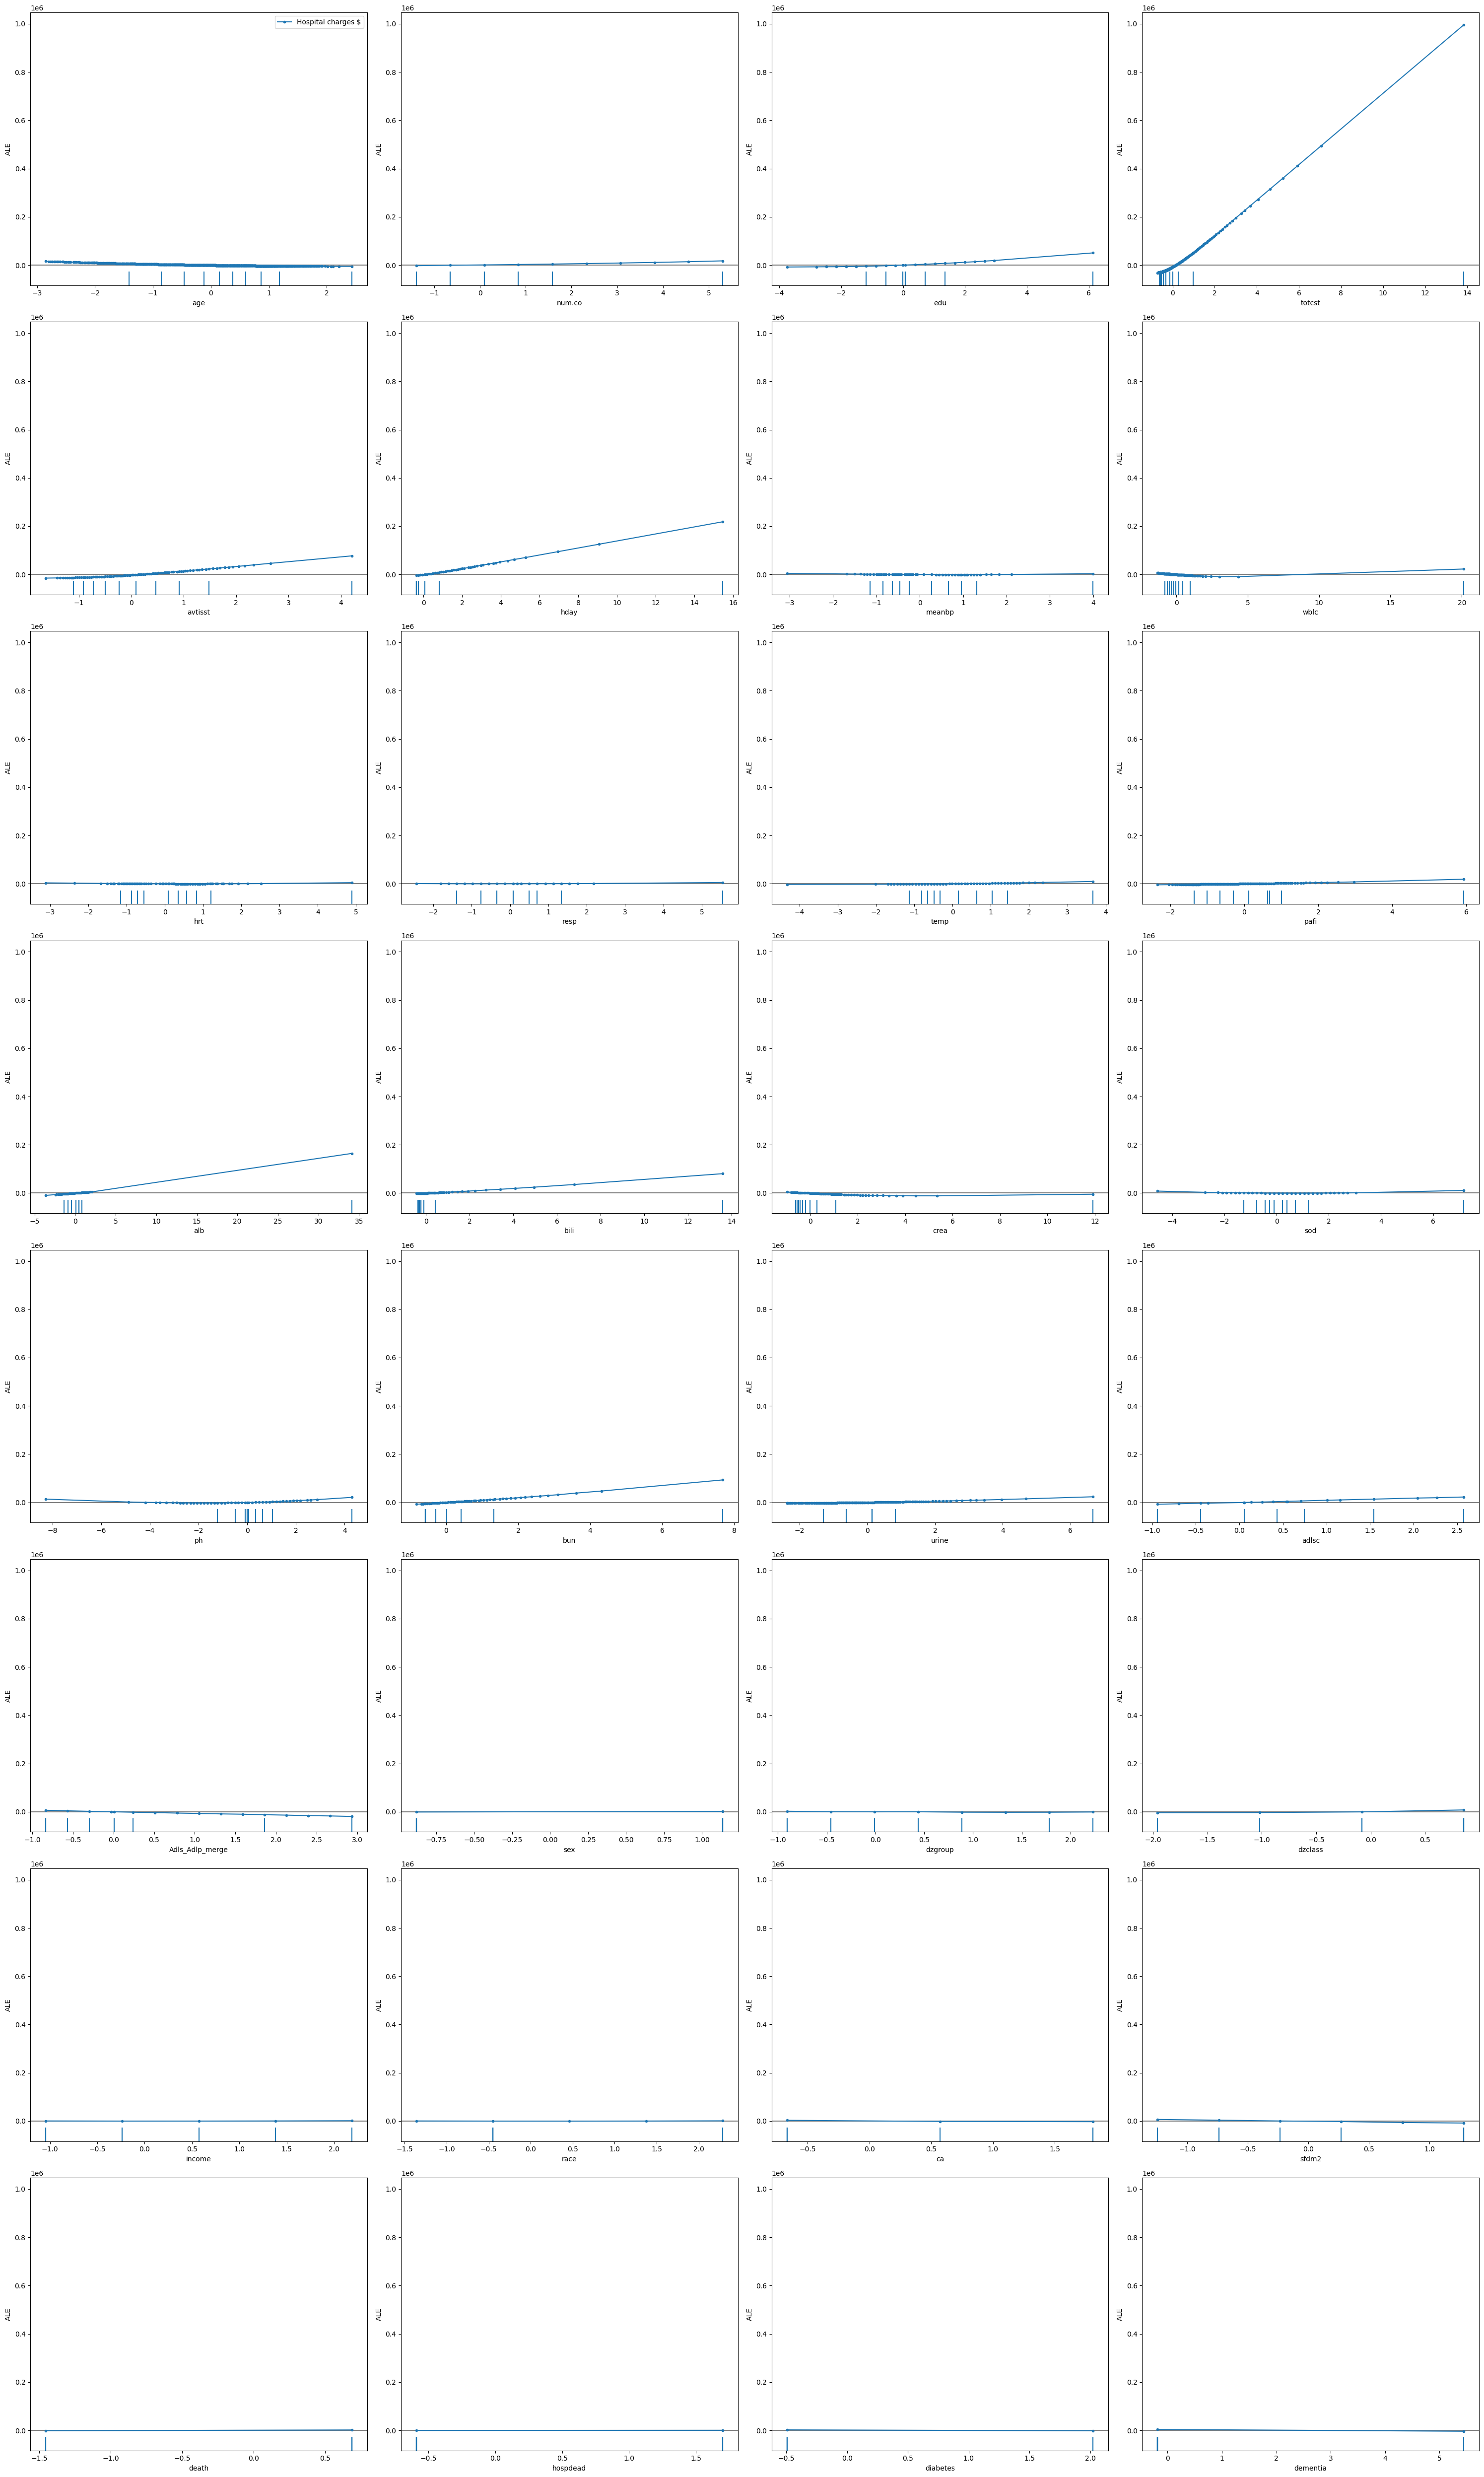

In [77]:
from alibi.explainers import ALE, plot_ale

feature_names = features_network.columns  
# Crear el explicador ALE
NeuralNetwork_ale = ALE(model.predict, feature_names=feature_names, target_names=['Hospital charges $'])

# Calcular ALE para el conjunto de entrenamiento
exp = NeuralNetwork_ale.explain(X_scaled_train_val_network)

# Graficar los resultados
plot_ale(exp, n_cols=4, fig_kw={'figwidth': 30, 'figheight': 50})

plt.show()

The graphs presented show the Local Cumulative Effects (ALE) analysis of a model's predictions of hospital charges. Each trace illustrates how the average model estimate changes when one independent variable changes, while maintaining the observed distribution of the others.

For variables such as “age”, “num.co”, “edu” and others, the ALE curves remain almost flat and close to zero, indicating minimal influence. Since no significant increase or decrease is observed as these variables change, it is concluded that the model does not rely heavily on them to adjust hospital charges. On their own, they do not induce a relevant variation in the estimated response.

On the other hand, the variable “totcst” shows a clearly ascending and very pronounced slope. As its values ​​increase, the average model prediction increases considerably, suggesting a direct and powerful relationship between “totcst” and predicted hospital charges. This variable exerts a predominant impact on the output of the model, eclipsing the influence of the rest of the characteristics analyzed.

However, there are also variables with slopes that, without being as steep as that of “totcst”, are not completely close to zero. These variables, although less determining, provide additional information that allows for a better fit and refinement in the final prediction. Overall, “totcst” provides most of the information used by the model, while variables with slopes other than zero contribute to further refining the estimate.